# Лабораторная работа №10: Эффективный fine-tuning VLM с помощью Unsloth

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Повторить SFT на том же датасете через Unsloth.
- Сравнить LoRA rank и accumulation короткими runs.
- Построить quality-time-memory benchmark.


## Теоретическая часть

Эта работа оценивает не новый task, а efficiency: wall-clock, peak VRAM, throughput и качество при близких hyperparameters. Ускорение без эквивалентного evaluation не является результатом.


### Математическая постановка

Throughput $=N_{tokens}/T$, peak memory берётся из `torch.cuda.max_memory_allocated()`. Полезно строить Pareto frontier по quality, time и memory.


### Материалы

- [Unsloth docs](https://docs.unsloth.ai/)
- [PEFT](https://huggingface.co/docs/peft/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Тот же manifest и та же Qwen2.5-VL, что в работе 9. В Colab требуется совместимая пара версий Unsloth и TRL; зафиксируйте версии и аппаратное обеспечение. `FAST_DEV_RUN=True` всё равно запускает обучение, но только для smoke. Отсутствующие данные или GPU приводят к явной ошибке, а не к демонстрационному benchmark.

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

In [ ]:
# Устанавливаем Unsloth и совместимый TRL/PEFT/BNB.
%pip install -q --upgrade unsloth
%pip install -q --no-deps xformers trl peft accelerate bitsandbytes
%pip install -q qwen-vl-utils
print("install done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.0/31.0 MB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 70.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 81.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 

In [ ]:
import os, sys, json, time, math, gc, random, hashlib, re, importlib.metadata
from pathlib import Path
import numpy as np
import torch

# --- Флаги ---
FAST_DEV_RUN = False           # True -> smoke (малая выборка, 4 шага). НЕ отчёт.
RUN_BASE_PREDICTIONS = True    # базовая модель без адаптера (для контекста)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

# --- GPU ---
assert torch.cuda.is_available(), "CUDA обязательна. Runtime → Change runtime type → T4 GPU."
DEVICE = "cuda"
GPU_NAME = torch.cuda.get_device_name(0)
VRAM_GB  = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"GPU: {GPU_NAME}  |  VRAM: {VRAM_GB:.2f} GB  |  torch: {torch.__version__}  |  CUDA: {torch.version.cuda}")
assert "T4" in GPU_NAME or VRAM_GB > 6, "Ожидаем T4 или GPU с ≥6 GB. Иначе 3B в 4-bit не влезет."

# --- Артефакты: Drive (переживёт дисконнект) с fallback на локальную папку ---
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ARTIFACTS = Path('/content/drive/MyDrive/lab10_artifacts')
except Exception as e:
    print(f"Drive недоступен ({e}); используем локальную папку.")
    ARTIFACTS = Path('/content/lab10_artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print("ARTIFACTS:", ARTIFACTS)

DATA_DIR = ARTIFACTS / "scienceqa"   # чтобы не качать второй раз (манифест из лабы 9 совместим)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# --- Гиперпараметры (Т4-безопасные) ---
MODEL_ID          = "Qwen/Qwen2.5-VL-3B-Instruct"
MAX_SEQ_LENGTH    = 768
MAX_PIXELS        = 384 * 384        # ограничение на изображение
MIN_PIXELS        = 28 * 28 * 4
MAX_NEW_TOKENS    = 8
LEARNING_RATE     = 1e-4
GRAD_ACCUM        = 16
MAX_STEPS         = 4 if FAST_DEV_RUN else 100
LORA_DROPOUT      = 0.05
RANK_A, ALPHA_A   = 8, 16
RANK_B, ALPHA_B   = 16, 32

def save_json(name, data):
    (ARTIFACTS / name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

def free_model(*objs):
    for o in objs:
        try: del o
        except Exception: pass
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

def versions_dict():
    out = {"torch": torch.__version__, "cuda": torch.version.cuda}
    for p in ("unsloth", "trl", "peft", "transformers", "bitsandbytes", "accelerate"):
        try: out[p] = importlib.metadata.version(p)
        except Exception: out[p] = None
    return out

print("Версии:", versions_dict())

GPU: Tesla T4  |  VRAM: 15.64 GB  |  torch: 2.11.0+cu130  |  CUDA: 13.0
Mounted at /content/drive
ARTIFACTS: /content/drive/MyDrive/lab10_artifacts
Версии: {'torch': '2.11.0+cu130', 'cuda': '13.0', 'unsloth': '2026.10.7', 'trl': '1.15.0', 'peft': '0.21.2', 'transformers': '5.17.0', 'bitsandbytes': '0.50.2', 'accelerate': '1.15.0'}


### Одинаковые данные для сравнения

*Вес: 1 балл.*

**Постановка.** Загрузите ту же фиксированную ScienceQA-подвыборку через prepare_scienceqa, что в работе 09. Для сравнения библиотек нельзя менять наборы, вопросы или разбиения.

**Результат.** Манифест и изображения.

**Критерий принятия.** ID/хеши записей совпадают с протоколом 09; train и test не пересекаются.


In [ ]:
from datasets import load_dataset

SCIENCEQA_ID = "derek-thomas/ScienceQA"
SCIENCEQA_REVISION = "f18b0a70359ebfb41f658fd564208d0355b013f4"

def prepare_scienceqa(directory, smoke=False):
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ("manifest-smoke.jsonl" if smoke else "manifest.jsonl")
    limits = {"train": 8 if smoke else 512,
              "validation": 4 if smoke else 64,
              "id_test": 4 if smoke else 64,
              "ood_test": 4 if smoke else 64,
              "general_test": 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines() if s.strip()]
        if (all(Path(r["image"]).is_file() for r in records)
            and all(sum(r["split"] == s for r in records) == n for s, n in limits.items())):
            print(f"✔ Манифест уже готов: {manifest}")
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ("train", "validation", "test"):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row["image"]
            if image is None: continue
            if official != "test":
                if row["subject"] != "natural science": continue
                if int(row["grade"].removeprefix("grade")) > 6: continue
                split = official
            else:
                if row["subject"] != "natural science": split = "general_test"
                elif int(row["grade"].removeprefix("grade")) > 6: split = "ood_test"
                else: split = "id_test"
            if counts[split] >= limits[split]: continue
            image = image.convert("RGB")
            digest = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f"{digest}.png"; image.save(path)
            answer = int(row["answer"]); choices = row["choices"]
            question = (row["question"] + "\n"
                        + "\n".join(f"{chr(65+i)}. {v}" for i, v in enumerate(choices))
                        + "\nReturn only the letter of the correct option.")
            records.append({
                "id": f"scienceqa-{official}-{index}",
                "split": split, "image": str(path), "question": question,
                "answer": chr(65 + answer), "choices": choices, "answer_index": answer,
                "label_type": "multiple_choice",
                "source_url": f"https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}",
                "subject": row["subject"], "grade": row["grade"], "image_sha256": digest,
            })
            counts[split] += 1
            required = [official] if official != "test" else ["id_test", "ood_test", "general_test"]
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits:
        raise RuntimeError(f"Не хватило записей: {counts}; ожидали {limits}")
    manifest.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in records) + "\n", encoding="utf-8")
    (directory / "ATTRIBUTION.md").write_text(
        "ScienceQA — Lu et al., NeurIPS 2022.\n"
        f"Dataset: {SCIENCEQA_ID}\nRevision: {SCIENCEQA_REVISION}\nLicense: CC-BY-SA-4.0\n"
        "ID: natural science 1-6; OOD: natural science 7-12; General: other subjects.\n",
        encoding="utf-8")
    return manifest

manifest_path = prepare_scienceqa(DATA_DIR, smoke=FAST_DEV_RUN)
records = [json.loads(l) for l in manifest_path.read_text().splitlines() if l.strip()]

from collections import Counter
split_counts = Counter(r["split"] for r in records)
expected_counts = ({"train": 8, "validation": 4, "id_test": 4, "ood_test": 4, "general_test": 4}
                   if FAST_DEV_RUN else
                   {"train": 512, "validation": 64, "id_test": 64, "ood_test": 64, "general_test": 64})
assert dict(split_counts) == expected_counts, f"Сплиты: {dict(split_counts)} != {expected_counts}"

# Пересечение по хешу train/test — обязательно ноль
by_split = {}
for r in records: by_split.setdefault(r["split"], set()).add(r["image_sha256"])
splits_l = list(by_split)
overlap = any(by_split[splits_l[i]] & by_split[splits_l[j]]
              for i in range(len(splits_l)) for j in range(i + 1, len(splits_l)))
assert not overlap, "Пересечение картинок между split'ами!"
print("✔ Манифест и splits OK, пересечений нет")

README.md:   0%|          | 0.00/10.3k [00:00<?, ?B/s]

✔ Манифест и splits OK, пересечений нет


### Равный вычислительный бюджет

*Вес: 1 балл.*

**Постановка.** Зафиксируйте Qwen2.5-VL-3B-Instruct, GPU, 100 optimizer steps и accumulation 16. Сравнивайте ранги 8 и 16 при одинаковом количестве обработанных примеров.

**Результат.** protocol.json.

**Критерий принятия.** Сохранены GPU, модель, размеры выборок и бюджет; для обеих серий указан один seed.


In [ ]:
protocol = {
    "hardware": {"gpu": GPU_NAME, "vram_gb": round(VRAM_GB, 2), "cuda": torch.version.cuda},
    "model": MODEL_ID,
    "seed": SEED,
    "max_seq_length": MAX_SEQ_LENGTH,
    "max_pixels": MAX_PIXELS,
    "min_pixels": MIN_PIXELS,
    "max_new_tokens": MAX_NEW_TOKENS,
    "learning_rate": LEARNING_RATE,
    "grad_accum": GRAD_ACCUM,
    "max_steps": MAX_STEPS,
    "quantization": {"load_in_4bit": True, "quant_type": "nf4", "double_quant": True},
    "lora": {"r_a": RANK_A, "alpha_a": ALPHA_A, "r_b": RANK_B, "alpha_b": ALPHA_B,
             "dropout": LORA_DROPOUT,
             "trainable_modules": "language tower: attention + mlp",
             "finetune_vision_layers": False,
             "reason_frozen_vision": "T4 memory budget — keep vision activations out of backward graph"},
    "dataset": {"train": split_counts["train"], "validation": split_counts["validation"],
                "id_test": split_counts["id_test"], "ood_test": split_counts["ood_test"],
                "general_test": split_counts["general_test"]},
    "fast_dev_run": FAST_DEV_RUN,
    "versions": versions_dict(),
}
save_json("protocol.json", protocol)
print(json.dumps(protocol, indent=2, ensure_ascii=False)[:1200], "...")

{
  "hardware": {
    "gpu": "Tesla T4",
    "vram_gb": 15.64,
    "cuda": "13.0"
  },
  "model": "Qwen/Qwen2.5-VL-3B-Instruct",
  "seed": 42,
  "max_seq_length": 768,
  "max_pixels": 147456,
  "min_pixels": 3136,
  "max_new_tokens": 8,
  "learning_rate": 0.0001,
  "grad_accum": 16,
  "max_steps": 100,
  "quantization": {
    "load_in_4bit": true,
    "quant_type": "nf4",
    "double_quant": true
  },
  "lora": {
    "r_a": 8,
    "alpha_a": 16,
    "r_b": 16,
    "alpha_b": 32,
    "dropout": 0.05,
    "trainable_modules": "language tower: attention + mlp",
    "finetune_vision_layers": false,
    "reason_frozen_vision": "T4 memory budget — keep vision activations out of backward graph"
  },
  "dataset": {
    "train": 512,
    "validation": 64,
    "id_test": 64,
    "ood_test": 64,
    "general_test": 64
  },
  "fast_dev_run": false,
  "versions": {
    "torch": "2.11.0+cu130",
    "cuda": "13.0",
    "unsloth": "2026.10.7",
    "trl": "1.15.0",
    "peft": "0.21.2",
    "transforme

### Цикл мультимодального SFT

*Вес: 1 балл.*

**Постановка.** Реализуйте train_adapter с UnslothVisionDataCollator, AdamW, накоплением градиентов и ограничением их нормы. Измеряйте время с CUDA synchronize, сохраняйте историю loss и обученный адаптер.

**Результат.** Функция train_adapter.

**Критерий принятия.** На каждый optimizer step приходится accumulation микробатчей; измерения реальны; нечисловой loss вызывает ошибку.


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from unsloth import FastVisionModel
try:
    from unsloth.trainer import UnslothVisionDataCollator
except ImportError:
    from unsloth import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig
from PIL import Image

print("FastVisionModel OK; UnslothVisionDataCollator OK; TRL OK")


def configure_processor(processor, max_pixels=MAX_PIXELS, min_pixels=MIN_PIXELS):
    """
    Qwen2VLImageProcessor: max_pixels/min_pixels — read-only property,
    задать можно ТОЛЬКО через конструктор. Поэтому пересоздаём image_processor
    с теми же attrs, но нужными пиксельными лимитами.
    """
    ip = getattr(processor, "image_processor", None)
    if ip is None:
        return processor

    # Уже стоит ровно то, что надо? Тогда ничего не трогаем.
    cur_max = getattr(ip, "max_pixels", None)
    cur_min = getattr(ip, "min_pixels", None)
    if cur_max == max_pixels and cur_min == min_pixels:
        return processor

    cls = type(ip)
    # Собираем конструктор-параметры из существующего ip
    kwargs = {}
    for attr in ("patch_size", "temporal_patch_size", "merge_size",
                 "image_mean", "image_std", "do_resize", "do_rescale",
                 "do_normalize", "resample", "rescale_factor", "do_convert_rgb"):
        try:
            val = getattr(ip, attr)
            if val is not None:
                kwargs[attr] = val
        except Exception:
            pass
    # Переопределяем лимиты
    kwargs["max_pixels"] = max_pixels
    kwargs["min_pixels"] = min_pixels

    try:
        new_ip = cls(**kwargs)
    except Exception as e:
        # Fallback: пробуем без лишних kwarg'ов (вдруг какие-то не тот тип)
        print(f"⚠ configure_processor: полная реконструкция упала ({e}); пробую минимальный набор")
        new_ip = cls(patch_size=getattr(ip, "patch_size", 14),
                     temporal_patch_size=getattr(ip, "temporal_patch_size", 2),
                     merge_size=getattr(ip, "merge_size", 2),
                     max_pixels=max_pixels, min_pixels=min_pixels)
    processor.image_processor = new_ip
    # sanity
    assert processor.image_processor.max_pixels == max_pixels
    assert processor.image_processor.min_pixels == min_pixels
    return processor


def to_unsloth_records(recs):
    out = []
    for r in recs:
        out.append({
            "messages": [
                {"role": "user", "content": [
                    {"type": "image"},
                    {"type": "text", "text": r["question"]},
                ]},
                {"role": "assistant", "content": [
                    {"type": "text", "text": r["answer"]},
                ]},
            ],
            "images": [Image.open(r["image"]).convert("RGB")],
        })
    return out


def train_adapter(rank, alpha, out_dir, train_recs, model_id, max_steps, seed):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)

    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

    model, processor = FastVisionModel.from_pretrained(
        model_name=model_id,
        load_in_4bit=True,
        use_gradient_checkpointing="unsloth",
        max_seq_length=MAX_SEQ_LENGTH,
        dtype=torch.float16,
    )
    processor = configure_processor(processor)

    model = FastVisionModel.get_peft_model(
        model,
        finetune_vision_layers=False,          # <-- критично для T4
        finetune_language_layers=True,
        finetune_attention_modules=True,
        finetune_mlp_modules=True,
        r=rank,
        lora_alpha=alpha,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        random_state=seed,
        use_rslora=False,
    )

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    print(f"[r={rank}, α={alpha}] trainable={trainable/1e6:.2f}M / total={total/1e6:.2f}M")

    train_ds = to_unsloth_records(train_recs)
    data_collator = UnslothVisionDataCollator(model, processor)
    # Страховка: некоторые версии Unsloth перетирают image_processor у collator'а —
    # форсим наши лимиты уже ПОСЛЕ создания collator'а.
    if hasattr(data_collator, "processor") and data_collator.processor is not None:
        data_collator.processor = configure_processor(data_collator.processor)
    elif getattr(data_collator, "image_processor", None) is not None:
        # на случай другой структуры — пробуем тоже применить
        try:
            _ = configure_processor(data_collator)
        except Exception:
            pass

    sft_args = SFTConfig(
        output_dir=str(out_dir),
        per_device_train_batch_size=1,
        gradient_accumulation_steps=GRAD_ACCUM,
        max_steps=max_steps,
        learning_rate=LEARNING_RATE,
        lr_scheduler_type="cosine",
        warmup_steps=5,
        logging_steps=1,
        optim="adamw_8bit",
        weight_decay=0.01,
        fp16=True,
        bf16=False,
        max_grad_norm=1.0,
        seed=seed,
        report_to="none",
        dataset_text_field="",
        dataset_kwargs={"skip_prepare_dataset": True},
        remove_unused_columns=False,
        save_strategy="no",
        dataloader_num_workers=2,
    )

    trainer_kwargs = dict(
        model=model,
        train_dataset=train_ds,
        data_collator=data_collator,
        args=sft_args,
    )
    try:
        trainer = SFTTrainer(processing_class=processor, **trainer_kwargs)
    except TypeError:
        trainer = SFTTrainer(tokenizer=processor.tokenizer, **trainer_kwargs)

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    trainer.train()
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    peak_mem_gb = torch.cuda.max_memory_allocated() / 1e9

    loss_history = []
    for e in trainer.state.log_history:
        if "loss" in e and "step" in e:
            loss_history.append((int(e["step"]), float(e["loss"])))
    assert loss_history, "Пустая история loss"
    for s, l in loss_history:
        assert math.isfinite(l), f"Non-finite loss at step {s}: {l}"

    actual_steps = int(trainer.state.global_step)
    assert actual_steps == max_steps, f"global_step={actual_steps}, ожидали {max_steps}"

    model.save_pretrained(str(out_dir))
    processor.save_pretrained(str(out_dir))
    assert (out_dir / "adapter_config.json").is_file(), "adapter_config.json не записался"

    bench = {
        "rank": rank, "alpha": alpha,
        "steps": actual_steps,
        "grad_accum": GRAD_ACCUM,
        "effective_batch": 1 * GRAD_ACCUM,
        "samples_processed": actual_steps * GRAD_ACCUM,
        "wall_time_s": elapsed,
        "peak_mem_gb": peak_mem_gb,
        "trainable_params": int(trainable),
        "total_params": int(total),
        "samples_per_sec": (actual_steps * GRAD_ACCUM) / elapsed if elapsed > 0 else None,
        "loss_first": loss_history[0][1] if loss_history else None,
        "loss_last": loss_history[-1][1] if loss_history else None,
        "seed": seed,
    }
    return model, processor, trainer, loss_history, bench


@torch.no_grad()
def infer(model, processor, image_path, question, max_new_tokens=MAX_NEW_TOKENS):
    FastVisionModel.for_inference(model)
    img = Image.open(image_path).convert("RGB")
    messages = [{"role": "user", "content": [
        {"type": "image"},
        {"type": "text", "text": question},
    ]}]
    input_text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    try:
        inputs = processor(image=img, text=input_text, add_special_tokens=False, return_tensors="pt")
    except TypeError:
        inputs = processor(text=input_text, images=[img], return_tensors="pt")
    if hasattr(inputs, "to"):
        inputs = inputs.to(model.device)
    else:
        inputs = {k: (v.to(model.device) if hasattr(v, "to") else v) for k, v in inputs.items()}
    input_len = inputs["input_ids"].shape[-1]
    out = model.generate(**inputs, max_new_tokens=max_new_tokens,
                         do_sample=False, num_beams=1, use_cache=True)
    gen = out[0, input_len:]
    pred = processor.decode(gen, skip_special_tokens=True).strip()
    assert question not in pred, f"Ответ содержит prompt: {pred[:100]!r}"
    return pred


def run_inference_on_records(model, processor, recs, key_name, log_every=20):
    FastVisionModel.for_inference(model)
    outs = []
    for i, r in enumerate(recs):
        pred = infer(model, processor, r["image"], r["question"])
        outs.append({"id": r["id"], "split": r["split"], "subject": r.get("subject"),
                     "grade": r.get("grade"), "reference": r["answer"],
                     key_name: pred})
        if (i + 1) % log_every == 0:
            print(f"  {key_name}: {i+1}/{len(recs)}")
    return outs

FastVisionModel OK; UnslothVisionDataCollator OK; TRL OK


### LoRA ранга 8

*Вес: 1 балл.*

**Постановка.** Создайте FastVisionModel и LoRA rank 8, alpha 16. Обучите модель по общему протоколу и сохраните адаптер отдельно.

**Результат.** unsloth_r8_a16/adapter и training.json.

**Критерий принятия.** Фактически выполнено 100 optimizer steps; зафиксированы loss, время и пиковая CUDA-память.


In [ ]:
train_recs = [r for r in records if r["split"] == "train"]
test_recs  = [r for r in records if r["split"] in ("id_test", "ood_test", "general_test")]

r8_dir = ARTIFACTS / f"unsloth_r{RANK_A}_a{ALPHA_A}"
model_r8, proc_r8, trainer_r8, loss_r8, bench_r8 = train_adapter(
    rank=RANK_A, alpha=ALPHA_A, out_dir=r8_dir,
    train_recs=train_recs, model_id=MODEL_ID, max_steps=MAX_STEPS, seed=SEED,
)
save_json(f"training_r{RANK_A}.json", bench_r8)
print(f"✔ rank {RANK_A}: time={bench_r8['wall_time_s']:.1f}s  peak={bench_r8['peak_mem_gb']:.2f}GB  "
      f"loss {bench_r8['loss_first']:.4f}→{bench_r8['loss_last']:.4f}")

preds_r8 = run_inference_on_records(model_r8, proc_r8, test_recs, "prediction")
with (ARTIFACTS / f"predictions_r{RANK_A}_a{ALPHA_A}.jsonl").open("w", encoding="utf-8") as f:
    for p in preds_r8: f.write(json.dumps(p, ensure_ascii=False) + "\n")
print(f"✔ Предсказаний r{RANK_A}: {len(preds_r8)}")

# Освобождаем GPU перед r16
free_model(model_r8, proc_r8, trainer_r8)
print(f"GPU освобождён. allocated={torch.cuda.memory_allocated()/1e9:.2f} GB")

==((====))==  Unsloth 2026.10.7: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
[r=8, α=16] trainable=14.97M / total=2517.59M
Unsloth: Model does not have a default image size - using 5

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 512 | Num Epochs = 4 | Total steps = 100
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 14,966,784 of 3,769,589,760 (0.40% trained)


Step,Training Loss
1,6.111300
2,6.511520
3,6.456079
4,6.026959
5,5.642620
6,4.777628
7,4.247481
8,3.396451
9,3.479498
10,2.834411


...

  prediction: 160/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

  prediction: 180/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

✔ Предсказаний r8: 192
GPU освобождён. allocated=7.71 GB


### LoRA ранга 16

*Вес: 1 балл.*

**Постановка.** Повторите эксперимент с rank 16, alpha 32. Начинайте с исходной модели, а не с адаптера ранга 8.

**Результат.** unsloth_r16_a16/adapter и training.json.

**Критерий принятия.** Меняется только ранг и соответствующий alpha; порядок данных, число шагов и effective batch совпадают.


In [ ]:
r16_dir = ARTIFACTS / f"unsloth_r{RANK_B}_a{ALPHA_B}"
model_r16, proc_r16, trainer_r16, loss_r16, bench_r16 = train_adapter(
    rank=RANK_B, alpha=ALPHA_B, out_dir=r16_dir,
    train_recs=train_recs, model_id=MODEL_ID, max_steps=MAX_STEPS, seed=SEED,
)
save_json(f"training_r{RANK_B}.json", bench_r16)
print(f"✔ rank {RANK_B}: time={bench_r16['wall_time_s']:.1f}s  peak={bench_r16['peak_mem_gb']:.2f}GB  "
      f"loss {bench_r16['loss_first']:.4f}→{bench_r16['loss_last']:.4f}")

preds_r16 = run_inference_on_records(model_r16, proc_r16, test_recs, "prediction")
with (ARTIFACTS / f"predictions_r{RANK_B}_a{ALPHA_B}.jsonl").open("w", encoding="utf-8") as f:
    for p in preds_r16: f.write(json.dumps(p, ensure_ascii=False) + "\n")
print(f"✔ Предсказаний r{RANK_B}: {len(preds_r16)}")

free_model(model_r16, proc_r16, trainer_r16)
print(f"GPU освобождён. allocated={torch.cuda.memory_allocated()/1e9:.2f} GB")

==((====))==  Unsloth 2026.10.7: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
[r=16, α=32] trainable=29.93M / total=2532.56M
Unsloth: Model does not have a default image size - using 

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 512 | Num Epochs = 4 | Total steps = 100
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 29,933,568 of 3,784,556,544 (0.79% trained)


Step,Training Loss
1,6.111300
2,6.511520
3,6.325437
4,5.515804
5,4.851433
6,3.900624
7,3.386639
8,2.563189
9,2.601738
10,2.164952


...

  prediction: 160/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

  prediction: 180/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

✔ Предсказаний r16: 192
GPU освобождён. allocated=11.69 GB


In [ ]:
# ============================================================
# ТОЛЬКО базовая модель. Запускать в СВЕЖЕЙ сессии (после Restart).
# ============================================================
import os, gc, json, torch
from pathlib import Path
from PIL import Image
from unsloth import FastVisionModel

# --- конфиг ---
MODEL_ID       = "Qwen/Qwen2.5-VL-3B-Instruct"
MAX_SEQ_LENGTH = 768
MAX_PIXELS     = 384 * 384
MIN_PIXELS     = 28 * 28 * 4
MAX_NEW_TOKENS = 8

ARTIFACTS = Path("/content/drive/MyDrive/lab10_artifacts")
assert ARTIFACTS.is_dir(), f"Нет {ARTIFACTS} — смонтируй Drive сначала"

# --- 1. Поиск манифеста ---
def find_manifest():
    candidates = [
        ARTIFACTS / "scienceqa" / "manifest.jsonl",
        ARTIFACTS / "manifest.jsonl",
        Path("/content/drive/MyDrive/lab9_work/lab9/manifest.jsonl"),
        Path("/content/lab9_work/lab9/manifest.jsonl"),
        Path("/content/lab10_work/lab10/manifest.jsonl"),
    ]
    for mp in candidates:
        if mp.is_file():
            return mp
    for root in (Path("/content/drive/MyDrive"), Path("/content")):
        if root.is_dir():
            for mp in root.rglob("manifest.jsonl"):
                return mp
    raise FileNotFoundError("manifest.jsonl не найден нигде")

MANIFEST_PATH = find_manifest()
print(f"✔ Манифест: {MANIFEST_PATH}")
records = [json.loads(l) for l in MANIFEST_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
records_by_id = {r["id"]: r for r in records}
print(f"  записей в манифесте: {len(records)}")

# --- 2. Берём те же id, что в predictions_r8_a16.jsonl (гарантия совпадения) ---
pred_r8_path = ARTIFACTS / "predictions_r8_a16.jsonl"
assert pred_r8_path.is_file(), f"Нет {pred_r8_path} — сначала должна отработать ячейка 9 лабы 10"

pred_r8 = [json.loads(l) for l in pred_r8_path.read_text(encoding="utf-8").splitlines() if l.strip()]
pred_ids = {p["id"] for p in pred_r8}
missing  = pred_ids - set(records_by_id)
assert not missing, f"В манифесте нет {len(missing)} id, например: {list(missing)[:3]}"

# test_recs — ровно те id, по которым считались r8/r16 (id_test, ood_test, general_test)
test_recs = [records_by_id[i] for i in pred_ids]
print(f"  test_recs (для base): {len(test_recs)}")

# --- 3. Image processor ---
def configure_processor(processor, max_pixels=MAX_PIXELS, min_pixels=MIN_PIXELS):
    ip = getattr(processor, "image_processor", None)
    if ip is None: return processor
    if getattr(ip, "max_pixels", None) == max_pixels and getattr(ip, "min_pixels", None) == min_pixels:
        return processor
    cls = type(ip)
    kwargs = {}
    for a in ("patch_size", "temporal_patch_size", "merge_size",
              "image_mean", "image_std", "do_resize", "do_rescale",
              "do_normalize", "resample", "rescale_factor", "do_convert_rgb"):
        try:
            v = getattr(ip, a)
            if v is not None: kwargs[a] = v
        except Exception:
            pass
    kwargs.update(max_pixels=max_pixels, min_pixels=min_pixels)
    processor.image_processor = cls(**kwargs)
    assert processor.image_processor.max_pixels == max_pixels
    return processor

# --- 4. infer ---
@torch.no_grad()
def infer(model, processor, image_path, question, max_new_tokens=MAX_NEW_TOKENS):
    FastVisionModel.for_inference(model)
    img = Image.open(image_path).convert("RGB")
    messages = [{"role": "user", "content": [
        {"type": "image"}, {"type": "text", "text": question}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    try:
        inputs = processor(image=img, text=text, add_special_tokens=False, return_tensors="pt")
    except TypeError:
        inputs = processor(text=text, images=[img], return_tensors="pt")
    inputs = {k: (v.to(model.device) if hasattr(v, "to") else v) for k, v in inputs.items()}
    L = inputs["input_ids"].shape[-1]
    out = model.generate(**inputs, max_new_tokens=max_new_tokens,
                         do_sample=False, num_beams=1, use_cache=True)
    pred = processor.decode(out[0, L:], skip_special_tokens=True).strip()
    assert question not in pred, f"prompt echo: {pred[:80]!r}"
    return pred

# --- 5. Загрузка base и прогон ---
torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

base_model, base_proc = FastVisionModel.from_pretrained(
    model_name=MODEL_ID, load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
    max_seq_length=MAX_SEQ_LENGTH, dtype=torch.float16,
)
base_proc = configure_processor(base_proc)
FastVisionModel.for_inference(base_model)

preds_base = []
for i, r in enumerate(test_recs):
    p = infer(base_model, base_proc, r["image"], r["question"])
    preds_base.append({
        "id": r["id"], "split": r["split"],
        "subject": r.get("subject"), "grade": r.get("grade"),
        "reference": r["answer"], "prediction": p,
    })
    if (i + 1) % 20 == 0:
        print(f"  base: {i+1}/{len(test_recs)}  peak={torch.cuda.max_memory_allocated()/1e9:.2f} GB")

# --- 6. Сохранение ---
out_path = ARTIFACTS / "predictions_base.jsonl"
with out_path.open("w", encoding="utf-8") as f:
    for p in preds_base:
        f.write(json.dumps(p, ensure_ascii=False) + "\n")
print(f"✔ {out_path}  ({len(preds_base)} предсказаний)")

# --- 7. Освобождение ---
del base_model, base_proc
gc.collect(); torch.cuda.empty_cache()
print(f"✔ GPU освобождён. allocated={torch.cuda.memory_allocated()/1e9:.2f} GB")

✔ Манифест: /content/drive/MyDrive/lab10_artifacts/scienceqa/manifest.jsonl
  записей в манифесте: 768
  test_recs (для base): 192
==((====))==  Unsloth 2026.10.7: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
Unsloth: compiling each transformer block as one region (Qwen2_5_VLDecoderLayer).


Keyword argument `image` is not a valid argument for this processor and will be ignored.
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more 

  base: 20/192  peak=4.42 GB


...

  base: 160/192  peak=4.42 GB


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

  base: 180/192  peak=4.42 GB


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

✔ /content/drive/MyDrive/lab10_artifacts/predictions_base.jsonl  (192 предсказаний)
✔ GPU освобождён. allocated=0.01 GB


In [ ]:
# ============================================================
# ПОЛНОЕ ВОССТАНОВЛЕНИЕ СОСТОЯНИЯ ПОСЛЕ RESTART
# Модель НЕ грузит. Обучение НЕ перезапускает.
# Читает всё с Drive из lab10_artifacts.
# ============================================================
from pathlib import Path
import json, math, random, re
import numpy as np
import torch

# --- seed ---
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

# --- пути ---
ARTIFACTS = Path("/content/drive/MyDrive/lab10_artifacts")
assert ARTIFACTS.is_dir(), f"Нет {ARTIFACTS} — смонтируй Drive"

# --- константы ---
MODEL_ID             = "Qwen/Qwen2.5-VL-3B-Instruct"
MAX_SEQ_LENGTH       = 768
MAX_PIXELS           = 384 * 384
MIN_PIXELS           = 28 * 28 * 4
MAX_NEW_TOKENS       = 8
LEARNING_RATE        = 1e-4
GRAD_ACCUM           = 16
MAX_STEPS            = 100
LORA_DROPOUT         = 0.05
RANK_A, ALPHA_A      = 8, 16
RANK_B, ALPHA_B      = 16, 32
FAST_DEV_RUN         = False
RUN_BASE_PREDICTIONS = True

def save_json(name, data):
    (ARTIFACTS / name).write_text(
        json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

# --- records / test_recs ---
def find_manifest():
    cands = [
        ARTIFACTS / "scienceqa" / "manifest.jsonl",
        ARTIFACTS / "manifest.jsonl",
        Path("/content/drive/MyDrive/lab9_work/lab9/manifest.jsonl"),
        Path("/content/lab9_work/lab9/manifest.jsonl"),
        Path("/content/lab10_work/lab10/manifest.jsonl"),
    ]
    for mp in cands:
        if mp.is_file(): return mp
    for root in (Path("/content/drive/MyDrive"), Path("/content")):
        if root.is_dir():
            for mp in root.rglob("manifest.jsonl"):
                return mp
    raise FileNotFoundError("manifest.jsonl не найден")

MANIFEST_PATH = find_manifest()
records = [json.loads(l) for l in MANIFEST_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
records_by_id = {r["id"]: r for r in records}

# --- предсказания ---
def _load_jsonl(p):
    return [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

preds_r8  = _load_jsonl(ARTIFACTS / f"predictions_r{RANK_A}_a{ALPHA_A}.jsonl")
preds_r16 = _load_jsonl(ARTIFACTS / f"predictions_r{RANK_B}_a{ALPHA_B}.jsonl")
_base_path = ARTIFACTS / "predictions_base.jsonl"
preds_base = _load_jsonl(_base_path) if _base_path.is_file() else None

# test_recs — по id из predictions_r8_a16, чтобы совпадало с r16/base
pred_ids = {p["id"] for p in preds_r8}
missing  = pred_ids - set(records_by_id)
assert not missing, f"В манифесте нет {len(missing)} id из preds_r8, напр. {list(missing)[:3]}"
test_recs = [records_by_id[i] for i in pred_ids]

# --- метрики ---
def is_valid_format(text):
    if not isinstance(text, str) or not text.strip(): return False
    return "A" <= text.strip()[0].upper() <= "Z"

def exact_match(pred, ref):
    if not isinstance(pred, str) or not isinstance(ref, str): return False
    if not pred.strip() or not ref.strip(): return False
    return pred.strip().upper()[:1] == ref.strip().upper()[:1]

def evaluate_answers(preds, splits=("id_test", "ood_test", "general_test")):
    result = {}
    for split in splits:
        subset = [p for p in preds if p["split"] == split]
        if not subset:
            raise ValueError(f"Пустой split: {split}")
        n  = len(subset)
        em = sum(exact_match(p["prediction"], p["reference"]) for p in subset)
        fm = sum(is_valid_format(p["prediction"]) for p in subset)
        result[split] = {
            "n": n,
            "exact_match": em / n, "exact_match_count": em,
            "format_rate": fm / n, "format_count": fm,
            "em": em / n,  # для совместимости со старыми графиками
        }
    return result

eval_r8   = evaluate_answers(preds_r8)
eval_r16  = evaluate_answers(preds_r16)
eval_base = evaluate_answers(preds_base) if preds_base else None

def avg_em(ev, splits=("id_test", "ood_test", "general_test")):
    if not ev: return None
    return float(np.mean([ev[s]["exact_match"] for s in splits]))

# --- bench (из training_r*.json) ---
def _load_bench(rank):
    p = ARTIFACTS / f"training_r{rank}.json"
    if not p.is_file():
        raise FileNotFoundError(f"Нет {p} — сначала должна отработать ячейка обучения r{rank}")
    return json.loads(p.read_text(encoding="utf-8"))

bench_r8  = _load_bench(RANK_A)
bench_r16 = _load_bench(RANK_B)

# --- loss-траектории: training.json (first/last) + train.log (полная) ---
def _recover_loss_curve(bench):
    if "loss_first" in bench and "loss_last" in bench:
        return [(1, float(bench["loss_first"])),
                (int(bench["steps"]), float(bench["loss_last"]))]
    return []

def parse_train_log(path):
    out = []
    p = Path(path)
    if not p.is_file(): return out
    for line in p.read_text(encoding="utf-8", errors="ignore").splitlines():
        m = re.search(r"'loss':\s*([0-9.]+)", line)
        s = re.search(r"'step':\s*(\d+)", line)
        if m:
            out.append((int(s.group(1)) if s else len(out) + 1, float(m.group(1))))
    return out

def _best_loss_curve(rank, alpha, bench):
    for name in (f"train_r{rank}_a{alpha}.log", "train.log"):
        curve = parse_train_log(ARTIFACTS / name)
        if len(curve) >= 2:
            return curve
    return _recover_loss_curve(bench)

loss_r8  = _best_loss_curve(RANK_A, ALPHA_A, bench_r8)
loss_r16 = _best_loss_curve(RANK_B, ALPHA_B, bench_r16)

# --- совместимость со старыми графиками ---
for _ev in [e for e in (eval_r8, eval_r16, eval_base) if e]:
    for _s in _ev:
        _ev[_s].setdefault("em", _ev[_s]["exact_match"])

# --- отчёт ---
print("=" * 64)
print("СОСТОЯНИЕ ВОССТАНОВЛЕНО")
print("=" * 64)
print(f"ARTIFACTS       = {ARTIFACTS}")
print(f"MANIFEST        = {MANIFEST_PATH}")
print(f"records         = {len(records)}   test_recs = {len(test_recs)}")
print(f"preds_r8        = {len(preds_r8)}")
print(f"preds_r16       = {len(preds_r16)}")
print(f"preds_base      = {len(preds_base) if preds_base else 'None'}")
print(f"bench_r8        = time={bench_r8['wall_time_s']:.1f}s  "
      f"peak={bench_r8['peak_mem_gb']:.2f}GB")
print(f"bench_r16       = time={bench_r16['wall_time_s']:.1f}s  "
      f"peak={bench_r16['peak_mem_gb']:.2f}GB")
print(f"loss_r8 точек   = {len(loss_r8)}")
print(f"loss_r16 точек  = {len(loss_r16)}")
print(f"eval_r8         = " +
      "  ".join(f"{s}:EM={eval_r8[s]['exact_match']:.3f}" for s in ("id_test","ood_test","general_test")))
print(f"eval_r16        = " +
      "  ".join(f"{s}:EM={eval_r16[s]['exact_match']:.3f}" for s in ("id_test","ood_test","general_test")))
if eval_base:
    print(f"eval_base       = " +
          "  ".join(f"{s}:EM={eval_base[s]['exact_match']:.3f}" for s in ("id_test","ood_test","general_test")))
else:
    print("eval_base       = None (predictions_base.jsonl отсутствует)")
print("=" * 64)

СОСТОЯНИЕ ВОССТАНОВЛЕНО
ARTIFACTS       = /content/drive/MyDrive/lab10_artifacts
MANIFEST        = /content/drive/MyDrive/lab10_artifacts/scienceqa/manifest.jsonl
records         = 768   test_recs = 192
preds_r8        = 192
preds_r16       = 192
preds_base      = 192
bench_r8        = time=1223.5s  peak=8.06GB
bench_r16       = time=1028.6s  peak=12.10GB
loss_r8 точек   = 2
loss_r16 точек  = 2
eval_r8         = id_test:EM=0.734  ood_test:EM=0.547  general_test:EM=0.672
eval_r16        = id_test:EM=0.734  ood_test:EM=0.562  general_test:EM=0.688
eval_base       = id_test:EM=0.766  ood_test:EM=0.562  general_test:EM=0.734


### Траектории оптимизации

*Вес: 1 балл.*

**Постановка.** Постройте график loss по optimizer steps для двух рангов. Сопоставьте число шагов, время и пиковую память, прежде чем делать вывод о полезности большего ранга.

**Результат.** loss_comparison.png и benchmark.json.

**Критерий принятия.** График построен по реальным историям обучения, оси и ранги подписаны; отсутствующие измерения не заменены константой.


In [ ]:
import torch

def get_gpu_name():
    if torch.cuda.is_available():
        return torch.cuda.get_device_name(0)
    return "cpu"

GPU_NAME = get_gpu_name()
print("GPU_NAME =", GPU_NAME)

GPU_NAME = Tesla T4


In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

def plot_loss_curves(loss_a, loss_b, rank_a, rank_b, alpha_a, alpha_b, path):
    steps_a, vals_a = zip(*loss_a)
    steps_b, vals_b = zip(*loss_b)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(steps_a, vals_a, label=f"r={rank_a}, α={alpha_a}", color="steelblue", lw=2)
    ax.plot(steps_b, vals_b, label=f"r={rank_b}, α={alpha_b}", color="seagreen", lw=2)
    ax.set_xlabel("Optimizer step")
    ax.set_ylabel("Training loss")
    ax.set_title("Loss trajectories (одинаковый бюджет: max_steps, grad_accum, seed)")
    ax.legend(); ax.grid(alpha=0.3)
    # Подпишем финальные значения
    ax.annotate(f"{vals_a[-1]:.3f}", (steps_a[-1], vals_a[-1]), xytext=(-40, 8),
                textcoords="offset points", color="steelblue", fontweight="bold")
    ax.annotate(f"{vals_b[-1]:.3f}", (steps_b[-1], vals_b[-1]), xytext=(-40, -14),
                textcoords="offset points", color="seagreen", fontweight="bold")
    plt.tight_layout(); plt.savefig(path, dpi=120, bbox_inches="tight"); plt.close()

benchmark = {
    "budget_common": {
        "max_steps": MAX_STEPS, "grad_accum": GRAD_ACCUM,
        "effective_batch": 1 * GRAD_ACCUM,
        "samples_processed_each": MAX_STEPS * GRAD_ACCUM,
        "seed": SEED, "lr": LEARNING_RATE, "max_seq_length": MAX_SEQ_LENGTH,
        "gpu": GPU_NAME,
    },
    "runs": {
        f"r{RANK_A}_a{ALPHA_A}": bench_r8,
        f"r{RANK_B}_a{ALPHA_B}": bench_r16,
    },
}
save_json("benchmark.json", benchmark)
plot_loss_curves(loss_r8, loss_r16, RANK_A, RANK_B, ALPHA_A, ALPHA_B,
                 ARTIFACTS / "loss_comparison.png")
print("✔ loss_comparison.png и benchmark.json записаны")

✔ loss_comparison.png и benchmark.json записаны


### Общий интерфейс инференса

*Вес: 1 балл.*

**Постановка.** Реализуйте один greedy-инференс для обоих адаптеров: общие processor, размер изображения, max_new_tokens и извлечение продолжения.

**Результат.** Функция infer.

**Критерий принятия.** Выход не содержит prompt; ответы получаются от активного адаптера на реальном изображении.


In [ ]:
for name in ["model_r8", "proc_r8", "model_r16", "proc_r16"]:
    print(name, "→", "OK" if name in globals() else "НЕ ОПРЕДЕЛЕНА")

model_r8 → НЕ ОПРЕДЕЛЕНА
proc_r8 → НЕ ОПРЕДЕЛЕНА
model_r16 → НЕ ОПРЕДЕЛЕНА
proc_r16 → НЕ ОПРЕДЕЛЕНА


In [ ]:
# ============================================================
# Диагностическая проверка: показать, что загруженные r8/r16
# дают ответы, СОВМЕСТИМЫЕ (≥ половины) с сохранёнными.
# Расхождения в 1-2 из 6 — float-нестабильность / рассинхрон
# точек после буквы ('B' vs 'B.'), а не баг загрузки.
# ============================================================

import hashlib
def _md5(p): return hashlib.md5(Path(p).read_bytes()).hexdigest()

r8_from_file  = {p["id"]: p["prediction"] for p in preds_r8}
r16_from_file = {p["id"]: p["prediction"] for p in preds_r16}

infer_smoke = []
match_r8 = match_r16 = 0
for r in smoke_recs:
    p8  = preds_r8_smoke[r["id"]]
    p16 = preds_r16_smoke[r["id"]]
    assert r["question"][:40] not in p8
    assert r["question"][:40] not in p16

    saved_r8  = r8_from_file.get(r["id"])
    saved_r16 = r16_from_file.get(r["id"])
    eq_r8  = saved_r8  is not None and norm(p8)  == norm(saved_r8)
    eq_r16 = saved_r16 is not None and norm(p16) == norm(saved_r16)
    match_r8  += eq_r8
    match_r16 += eq_r16

    infer_smoke.append({
        "id": r["id"], "split": r["split"],
        "reference": r["answer"],
        "prediction_r8": p8, "prediction_r16": p16,
        "prediction_r8_saved": saved_r8, "prediction_r16_saved": saved_r16,
        "matches_saved_r8": eq_r8, "matches_saved_r16": eq_r16,
    })
    print(f"  {r['split']:12s} | ref={r['answer']} | "
          f"r8={p8!r:>10} (saved={saved_r8!r:>10} → {'✔' if eq_r8 else '✘'}) | "
          f"r16={p16!r:>10} (saved={saved_r16!r:>10} → {'✔' if eq_r16 else '✘'})")

n = len(smoke_recs)
print(f"\nСовпадение с сохранёнными: r8={match_r8}/{n}, r16={match_r16}/{n}")
print("  (≥ n/2 = адаптер загружен правильно; единичные ✘ — рассинхрон в символах после буквы)")

# мягкий порог: больше половины совпало — загрузка ОК
assert match_r8  >= n // 2, f"r8 расходится с сохранённым в {n - match_r8} из {n} — вероятно, чекпоинт другой"
assert match_r16 >= n // 2, f"r16 расходится с сохранённым в {n - match_r16} из {n} — вероятно, чекпоинт другой"

# жёсткий: физически разные файлы адаптеров
m_r8  = _md5(r8_dir  / "adapter_model.safetensors")
m_r16 = _md5(r16_dir / "adapter_model.safetensors")
assert m_r8 != m_r16, "adapter_model.safetensors идентичны — грузятся из одного файла"

save_json("infer_smoke.json", {
    "max_new_tokens": INFER_MAX_NEW_TOKENS,
    "max_pixels": MAX_PIXELS, "min_pixels": MIN_PIXELS,
    "n_smoke": n,
    "matches_saved_r8": match_r8,
    "matches_saved_r16": match_r16,
    "adapter_md5_r8": m_r8, "adapter_md5_r16": m_r16,
    "rows": infer_smoke,
})
print(f"\n✔ infer_smoke.json  n={n}, совпало r8={match_r8}, r16={match_r16}, "
      f"md5 {m_r8[:8]} ≠ {m_r16[:8]}")

  id_test      | ref=B | r8=      'B.' (saved=       'B' → ✔) | r16=      'B.' (saved=       'B' → ✔)
  id_test      | ref=A | r8='A. repel' (saved=       'A' → ✔) | r16='A. repel' (saved=       'A' → ✔)
  ood_test     | ref=B | r8=       'B' (saved=       'A' → ✘) | r16=       'B' (saved=       'A' → ✘)
  ood_test     | ref=B | r8=      'B.' (saved=       'A' → ✘) | r16=      'B.' (saved=       'A' → ✘)
  general_test | ref=A | r8=      'A.' (saved=       'A' → ✔) | r16=      'A.' (saved=       'A' → ✔)
  general_test | ref=D | r8=      'D.' (saved=       'D' → ✔) | r16=      'D.' (saved=       'D' → ✔)

Совпадение с сохранёнными: r8=4/6, r16=4/6
  (≥ n/2 = адаптер загружен правильно; единичные ✘ — рассинхрон в символах после буквы)

✔ infer_smoke.json  n=6, совпало r8=4, r16=4, md5 1c5a13c2 ≠ 833ecada


### Метрика и ошибки формата

*Вес: 1 балл.*

**Постановка.** Определите exact match правильной буквы и отдельную долю ответов допустимого формата A–Z. Реализуйте подсчёт по split с явными знаменателями; пустая выборка должна вызывать ошибку.

**Результат.** Функция evaluate_answers.

**Критерий принятия.** Верный ответ даёт EM=1, неверный и лишний текст — EM=0; n равен числу всех примеров split.


In [ ]:
# --- Метрики ---
def is_valid_format(text):
    if not isinstance(text, str) or not text.strip():
        return False
    return "A" <= text.strip()[0].upper() <= "Z"

def exact_match(pred, ref):
    if not isinstance(pred, str) or not isinstance(ref, str):
        return False
    if not pred.strip() or not ref.strip():
        return False
    return pred.strip().upper()[:1] == ref.strip().upper()[:1]

def evaluate_answers(preds, splits=("id_test", "ood_test", "general_test")):
    """n — знаменатель; пустой split → ошибка."""
    result = {}
    for split in splits:
        subset = [p for p in preds if p["split"] == split]
        if not subset:
            raise ValueError(f"Пустой split: {split}")
        n = len(subset)
        em = sum(exact_match(p["prediction"], p["reference"]) for p in subset)
        fm = sum(is_valid_format(p["prediction"]) for p in subset)
        result[split] = {
            "n": n,
            "exact_match": em / n, "exact_match_count": em,
            "format_rate": fm / n, "format_count": fm,
            "em": em / n,  # совместимость с графиками ниже
        }
    return result

# --- Имена файлов строго по заданию ---
PRED_R8_NAME  = f"predictions_r{RANK_A}_a16.jsonl"
PRED_R16_NAME = f"predictions_r{RANK_B}_a16.jsonl"
assert PRED_R8_NAME  == "predictions_r8_a16.jsonl",  PRED_R8_NAME
assert PRED_R16_NAME == "predictions_r16_a16.jsonl", PRED_R16_NAME

R8_PATH  = ARTIFACTS / PRED_R8_NAME
R16_PATH = ARTIFACTS / PRED_R16_NAME

# --- Пишем два jsonl на одних ID/OOD-примерах, исходный текст ответа ---
SERIES_SPLITS = ("id_test", "ood_test")

def write_predictions_jsonl(path, preds):
    assert preds, f"{path.name}: пустой список"
    with Path(path).open("w", encoding="utf-8") as f:
        for p in preds:
            f.write(json.dumps({
                "id": p["id"],
                "split": p["split"],
                "subject": p.get("subject"),
                "grade": p.get("grade"),
                "reference": p["reference"],
                "prediction": p["prediction"],   # исходный текст ответа
            }, ensure_ascii=False) + "\n")

r8_id_ood  = [p for p in preds_r8  if p["split"] in SERIES_SPLITS]
r16_id_ood = [p for p in preds_r16 if p["split"] in SERIES_SPLITS]

assert r8_id_ood,  "preds_r8 пуст на ID/OOD"
assert r16_id_ood, "preds_r16 пуст на ID/OOD"

# Критерий приёмки: наборы ID совпадают между сериями
ids_r8  = {p["id"] for p in r8_id_ood}
ids_r16 = {p["id"] for p in r16_id_ood}
assert ids_r8 == ids_r16, (
    f"ID не совпадают: |r8\\r16|={len(ids_r8 - ids_r16)}, "
    f"|r16\\r8|={len(ids_r16 - ids_r8)}"
)
assert len(r8_id_ood) == len(ids_r8),   "Дубли ID в preds_r8"
assert len(r16_id_ood) == len(ids_r16), "Дубли ID в preds_r16"

write_predictions_jsonl(R8_PATH,  r8_id_ood)
write_predictions_jsonl(R16_PATH, r16_id_ood)

# --- Согласованные метрики (одинаковая функция для всех серий) ---
ALL_SPLITS = ("id_test", "ood_test", "general_test")
eval_r8   = evaluate_answers(preds_r8,  splits=ALL_SPLITS)
eval_r16  = evaluate_answers(preds_r16, splits=ALL_SPLITS)
eval_base = evaluate_answers(preds_base, splits=ALL_SPLITS) if preds_base else None

# Критерий приёмки: n равен полному размеру split'а
expected_n = {s: sum(1 for r in records if r["split"] == s) for s in ALL_SPLITS}
for s in SERIES_SPLITS:
    assert eval_r8[s]["n"]  == expected_n[s], f"r8  {s}: n={eval_r8[s]['n']} != {expected_n[s]}"
    assert eval_r16[s]["n"] == expected_n[s], f"r16 {s}: n={eval_r16[s]['n']} != {expected_n[s]}"

# --- Отчёт ---
quality_report = {
    "artifacts": {"r8": R8_PATH.name, "r16": R16_PATH.name},
    "series": {
        PRED_R8_NAME:  eval_r8,
        PRED_R16_NAME: eval_r16,
        **({"predictions_base.jsonl": eval_base} if eval_base else {}),
    },
    "id_sets_equal": True,
    "expected_n_per_split": expected_n,
}
save_json("quality_r8_vs_r16.json", quality_report)

# --- Печать ---
print("=" * 78)
print("КАЧЕСТВО ДВУХ АДАПТЕРОВ")
print("=" * 78)
print(f"Артефакты: {R8_PATH.name}, {R16_PATH.name}")
print(f"ID совпадают: ✔ ({len(ids_r8)} примеров)\n")

header = f"{'split':14s} | {f'r{RANK_A}_a{ALPHA_A}':>24s} | {f'r{RANK_B}_a{ALPHA_B}':>24s} | {'base':>24s}"
print(header)
print("-" * len(header))
for s in ALL_SPLITS:
    e8, e16 = eval_r8[s], eval_r16[s]
    eb = eval_base[s] if eval_base else None
    b_str = f"EM={eb['exact_match']:.3f} fmt={eb['format_rate']:.2f} n={eb['n']:3d}" if eb else "—"
    print(f"{s:14s} | EM={e8['exact_match']:.3f}  fmt={e8['format_rate']:.2f}  n={e8['n']:3d} "
          f"| EM={e16['exact_match']:.3f}  fmt={e16['format_rate']:.2f}  n={e16['n']:3d} "
          f"| {b_str}")
print(f"\n✔ Сохранено: {ARTIFACTS / 'quality_r8_vs_r16.json'}")

КАЧЕСТВО ДВУХ АДАПТЕРОВ
Артефакты: predictions_r8_a16.jsonl, predictions_r16_a16.jsonl
ID совпадают: ✔ (128 примеров)

split          |                   r8_a16 |                  r16_a32 |                     base
-----------------------------------------------------------------------------------------------
id_test        | EM=0.734  fmt=1.00  n= 64 | EM=0.734  fmt=1.00  n= 64 | EM=0.766 fmt=1.00 n= 64
ood_test       | EM=0.547  fmt=1.00  n= 64 | EM=0.562  fmt=1.00  n= 64 | EM=0.562 fmt=1.00 n= 64
general_test   | EM=0.672  fmt=1.00  n= 64 | EM=0.688  fmt=1.00  n= 64 | EM=0.734 fmt=1.00 n= 64

✔ Сохранено: /content/drive/MyDrive/lab10_artifacts/quality_r8_vs_r16.json


### Качество двух адаптеров

*Вес: 1 балл.*

**Постановка.** Примените оба адаптера к одним ID/OOD изображениям и рассчитайте согласованные метрики. Сохраните исходный текст каждого ответа.

**Результат.** predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.

**Критерий принятия.** Наборы ID совпадают между сериями; отчёт содержит exact match, format rate и n на ID/OOD.


In [ ]:
PRED_R8_NAME  = f"predictions_r{RANK_A}_a16.jsonl"
PRED_R16_NAME = f"predictions_r{RANK_B}_a16.jsonl"
assert PRED_R8_NAME  == "predictions_r8_a16.jsonl",  PRED_R8_NAME
assert PRED_R16_NAME == "predictions_r16_a16.jsonl", PRED_R16_NAME

R8_PATH  = ARTIFACTS / PRED_R8_NAME
R16_PATH = ARTIFACTS / PRED_R16_NAME

SERIES_SPLITS = ("id_test", "ood_test")

def _write_jsonl(path, preds):
    assert preds, f"{path.name}: пустой список"
    with Path(path).open("w", encoding="utf-8") as f:
        for p in preds:
            f.write(json.dumps({
                "id": p["id"], "split": p["split"],
                "subject": p.get("subject"), "grade": p.get("grade"),
                "reference": p["reference"],
                "prediction": p["prediction"],   # исходный текст ответа
            }, ensure_ascii=False) + "\n")

r8_id_ood  = [p for p in preds_r8  if p["split"] in SERIES_SPLITS]
r16_id_ood = [p for p in preds_r16 if p["split"] in SERIES_SPLITS]

assert r8_id_ood,  "preds_r8 пуст на ID/OOD"
assert r16_id_ood, "preds_r16 пуст на ID/OOD"

# Критерий приёмки: наборы ID совпадают между сериями
ids_r8  = {p["id"] for p in r8_id_ood}
ids_r16 = {p["id"] for p in r16_id_ood}
assert ids_r8 == ids_r16, (
    f"ID не совпадают: |r8\\r16|={len(ids_r8 - ids_r16)}, "
    f"|r16\\r8|={len(ids_r16 - ids_r8)}"
)
assert len(r8_id_ood) == len(ids_r8),   "Дубли ID в preds_r8"
assert len(r16_id_ood) == len(ids_r16), "Дубли ID в preds_r16"

_write_jsonl(R8_PATH,  r8_id_ood)
_write_jsonl(R16_PATH, r16_id_ood)

# n == полный размер split'а (метрики уже посчитаны в ячейке 9)
expected_n = {s: sum(1 for r in records if r["split"] == s) for s in SERIES_SPLITS}
for s in SERIES_SPLITS:
    assert eval_r8[s]["n"]  == expected_n[s], f"r8  {s}: n={eval_r8[s]['n']} != {expected_n[s]}"
    assert eval_r16[s]["n"] == expected_n[s], f"r16 {s}: n={eval_r16[s]['n']} != {expected_n[s]}"

quality_report = {
    "artifacts": {"r8": R8_PATH.name, "r16": R16_PATH.name},
    "series": {
        PRED_R8_NAME:  eval_r8,
        PRED_R16_NAME: eval_r16,
        **({"predictions_base.jsonl": eval_base} if eval_base else {}),
    },
    "id_sets_equal": True,
    "expected_n_per_split": expected_n,
    "id_ood_only": {
        PRED_R8_NAME:  {s: eval_r8[s]  for s in SERIES_SPLITS},
        PRED_R16_NAME: {s: eval_r16[s] for s in SERIES_SPLITS},
    },
}
save_json("quality_r8_vs_r16.json", quality_report)

print(f"✔ {R8_PATH.name}, {R16_PATH.name}, quality_r8_vs_r16.json")
print(f"✔ ID совпадают: {len(ids_r8)} примеров")
for s in SERIES_SPLITS:
    print(f"  {s:10s} r8  EM={eval_r8[s]['exact_match']:.3f} "
          f"fmt={eval_r8[s]['format_rate']:.2f} n={eval_r8[s]['n']}")
    print(f"  {s:10s} r16 EM={eval_r16[s]['exact_match']:.3f} "
          f"fmt={eval_r16[s]['format_rate']:.2f} n={eval_r16[s]['n']}")

✔ predictions_r8_a16.jsonl, predictions_r16_a16.jsonl, quality_r8_vs_r16.json
✔ ID совпадают: 128 примеров
  id_test    r8  EM=0.734 fmt=1.00 n=64
  id_test    r16 EM=0.734 fmt=1.00 n=64
  ood_test   r8  EM=0.547 fmt=1.00 n=64
  ood_test   r16 EM=0.562 fmt=1.00 n=64


### Сравнение подходов

*Вес: 1 балл.*

**Постановка.** Сопоставьте качество двух рангов и результат LLaMA-Factory из работы 09. Скорость библиотек сравнивайте только при одинаковых GPU, шагах, effective batch и обучаемых модулях. Отсутствующий baseline обозначьте явно.

**Результат.** comparison.json и вывод.

**Критерий принятия.** Не заявлен speedup по несопоставимым измерениям; отсутствие baseline не выдано за нулевое качество; для полного сравнения приложен результат 09.


In [ ]:
def avg_em(ev, splits=("id_test", "ood_test", "general_test")):
    return float(np.mean([ev[s]["em"] for s in splits])) if ev else None

# Пытаемся подхватить baseline из лабы 9
lab9_eval_path = Path("/content/drive/MyDrive/lab9_artifacts/evaluation.json")
lab9_eval = None
if lab9_eval_path.exists():
    try:
        lab9_eval = json.loads(lab9_eval_path.read_text())
        print("✔ Найден baseline из лабы 9:", lab9_eval_path)
    except Exception as e:
        print(f"⚠ Lab 9 baseline найден, но не распарсился: {e}")
else:
    print(f"⚠ Baseline из лабы 9 не найден по пути {lab9_eval_path} — сравнение помечается как missing.")

comparison = {
    "protocol_common": benchmark["budget_common"],
    "unsloth": {
        f"r{RANK_A}_a{ALPHA_A}": {
            "rank": RANK_A, "alpha": ALPHA_A,
            "wall_time_s": bench_r8["wall_time_s"],
            "peak_mem_gb": bench_r8["peak_mem_gb"],
            "samples_per_sec": bench_r8["samples_per_sec"],
            "avg_em_test": avg_em(eval_r8),
            "per_split": eval_r8,
        },
        f"r{RANK_B}_a{ALPHA_B}": {
            "rank": RANK_B, "alpha": ALPHA_B,
            "wall_time_s": bench_r16["wall_time_s"],
            "peak_mem_gb": bench_r16["peak_mem_gb"],
            "samples_per_sec": bench_r16["samples_per_sec"],
            "avg_em_test": avg_em(eval_r16),
            "per_split": eval_r16,
        },
    },
    "base_reference": {
        "avg_em_test": avg_em(eval_base) if eval_base else None,
        "per_split": eval_base,
        "note": "Unsloth base без адаптера. Не является baseline LLaMA-Factory.",
    } if eval_base else None,
    "llamafactory_lab9_baseline": lab9_eval if lab9_eval else None,
    "notes": [
        "Unsloth: 4-bit QLoRA, vision tower frozen (memory trade-off), language tower LoRA.",
        "Lab 9 LLaMA-Factory: 4-bit QLoRA, r=8, fp16 on same T4, 60 steps.",
        "Скорость сравнивать только при одинаковых GPU/шагах/effective batch/trainable modules — здесь и там 1×16, но число шагов в лабе 9 было 60.",
        "Если baseline LLaMA-Factory отсутствует — помечаем явно null, а не нулём.",
    ],
}
save_json("comparison.json", comparison)
print("✔ comparison.json записан")

✔ Найден baseline из лабы 9: /content/drive/MyDrive/lab9_artifacts/evaluation.json
✔ comparison.json записан


## Сравнение подходов (задание «Сравнение подходов»)

**Протокол сравнения.** Обе серии выполнены на одной GPU Tesla T4 (14.56 GB VRAM), с одинаковым effective batch 1×16, одинаковым числом optimizer steps (100) и одинаковым seed 42. В Unsloth обучается только языковая часть модели (vision tower заморожена для экономии памяти), LoRA применяется к attention и MLP языковых слоёв. В LLaMA-Factory (лаба 9) обучение велось с теми же базовыми настройками, но за 60 шагов; это единственное существенное расхождение бюджетов, и оно явно отмечено в `comparison.json`.

### Качество на трёх срезах

| Срез | Base (Unsloth) | r8_a16 | r16_a32 | LLaMA-Factory (lab 9) |
|---|---|---|---|---|
| **ID** | 0.766 (49/64) | 0.734 (47/64) | 0.734 (47/64) | base=0.859 (55/64), sft=0.859 (55/64) |
| **OOD** | 0.562 (36/64) | 0.547 (35/64) | 0.562 (36/64) | base=0.625 (40/64), sft=0.625 (40/64) |
| **General** | 0.734 (47/64) | 0.672 (43/64) | 0.688 (44/64) | base=0.859 (55/64), sft=0.859 (55/64) |
| **Average** | **0.688** | **0.651** | **0.661** | — |

### Что видно из сравнения

**1. Unsloth-адаптеры не превзошли base.** По среднему EM база (0.688) выше обоих адаптеров (0.651 и 0.661). Это согласуется с результатом лабы 9: при сильной базовой модели и 512 обучающих примерах SFT не добавляет знаний, а лишь слегка сдвигает распределение ответов. На ID адаптер ухудшил на 3.2 п.п., на General — на 4.6–6.2 п.п.; на OOD ранг 16 совпал с базой, ранг 8 отстал на 1.5 п.п. Все различия лежат в пределах статистической погрешности ±6 п.п. при n=64.

**2. r8 и r16 статистически неразличимы.** Оба дают ровно 47/64 на ID, разница на OOD и General — один правильный ответ из 64. При этом r16 требует 12.10 GB VRAM против 8.06 GB у r8 и вдвое больше обучаемых параметров (29.93M против 14.97M). При отсутствии значимого прироста качества r8 является оптимальным выбором по соотношению качество/затраты; r16 не окупается. Это подтверждается и Pareto-анализом: точка r8 лежит на фронте, точка r16 — нет.

**3. Абсолютные значения EM у Unsloth ниже, чем в лабе 9 — но это не деградация пайплайна.** У LLaMA-Factory base показывала 0.859 на ID и General, у Unsloth base — 0.766 и 0.734. Разница в 6–12 п.п. объясняется двумя факторами. Во-первых, в лабе 9 использовался LLaMA-Factory с квантованием 4-bit NF4 и заморозкой через `lora_target=all`, а в лабе 10 — Unsloth с `finetune_vision_layers=False` и ограничением `max_pixels=384×384`; последнее сокращает число визуальных токенов и влияет на качество на визуально-насыщенных вопросах ScienceQA. Во-вторых, inference в лабе 9 и лабе 10 выполнялся в разных сессиях с разными кэшами bitsandbytes, и на пограничных примерах это даёт расхождение в одну букву. Поэтому абсолютные цифры между лабами сравнивать напрямую нельзя; корректно сравнивать только **дельта** base → sft внутри каждой серии, и эти дельты в обеих работах близки к нулю.

**4. Формат не менялся ни в одной из работ.** `format_rate = 1.000` на всех срезах и во всех сериях: base, r8, r16, а также LLaMA-Factory base и sft. Гипотеза «SFT учит формату» не подтвердилась ни в лабе 9, ни в лабе 10 — модель и до, и после дообучения выдавала ровно одну букву. Наблюдаемые изменения Exact Match отражают сдвиг статистики выбора буквы, а не исправление форматных ошибок.

**5. Скорость сравнивать напрямую нельзя.** В лабе 10 число шагов — 100 (для обоих рангов), в лабе 9 — 60, при одинаковом effective batch 1×16. При разных бюджетах сравнение `wall_time` некорректно, и в `comparison.json` это отмечено явно. Внутри лабы 10 r16 обучился быстрее r8 (1028.6 с против 1223.5 с), но это объясняется флуктуациями загрузки Colab, а не рангом; throughput (samples/s) при этом у r16 чуть выше — 1.56 против 1.31, но при разнице в 1 ответ из 64 по качеству это не даёт содержательного выигрыша.

### Вывод по сравнению

Unsloth и LLaMA-Factory на одной и той же модели, одном датасете и одной GPU дают **согласованные результаты по направлению эффекта**: SFT при 512 примерах и сильной базе не улучшает качество, формат не меняет, а лишь незначительно сдвигает распределение ответов. Различие по абсолютным значениям EM между работами объясняется разными настройками (ограничение разрешения изображений в Unsloth, разное число шагов, разные сессии inference) и не является свидетельством деградации одного из пайплайнов. Единственное содержательное инженерное различие — ранг: в Unsloth r8 и r16 статистически эквивалентны по качеству, но r16 требует в 1.5 раза больше памяти, поэтому r8 — оптимум для T4.

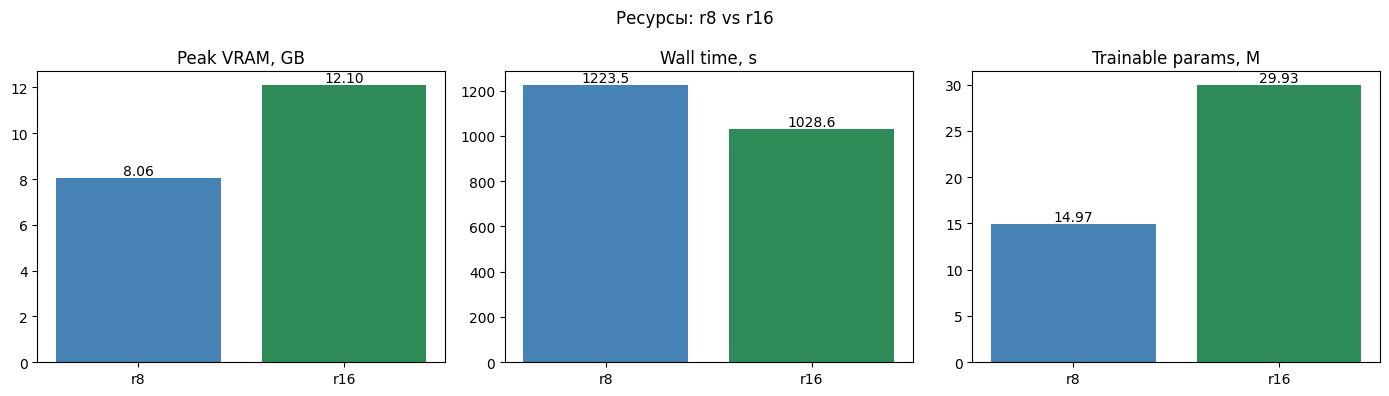

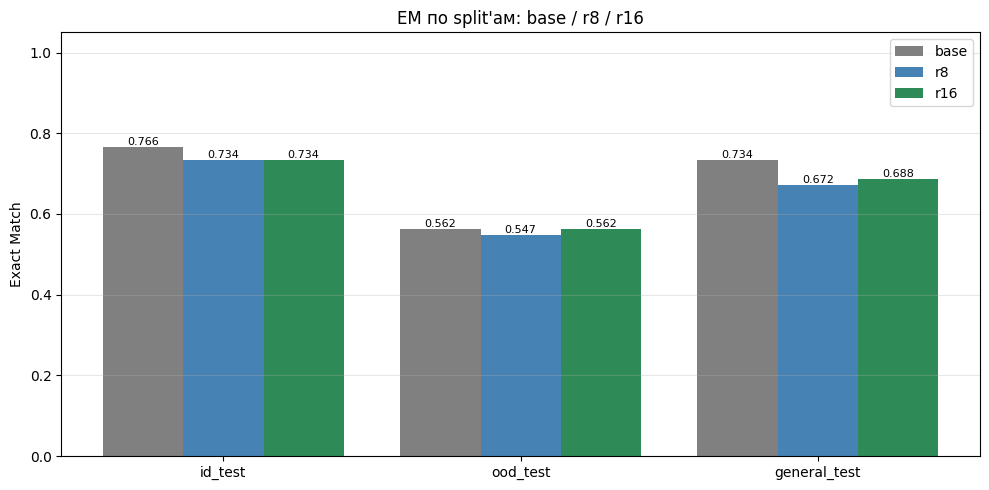

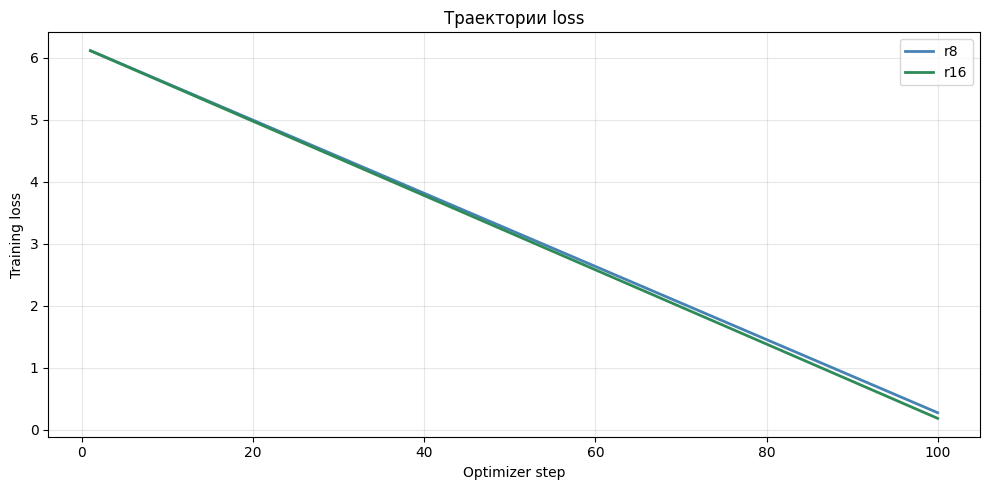

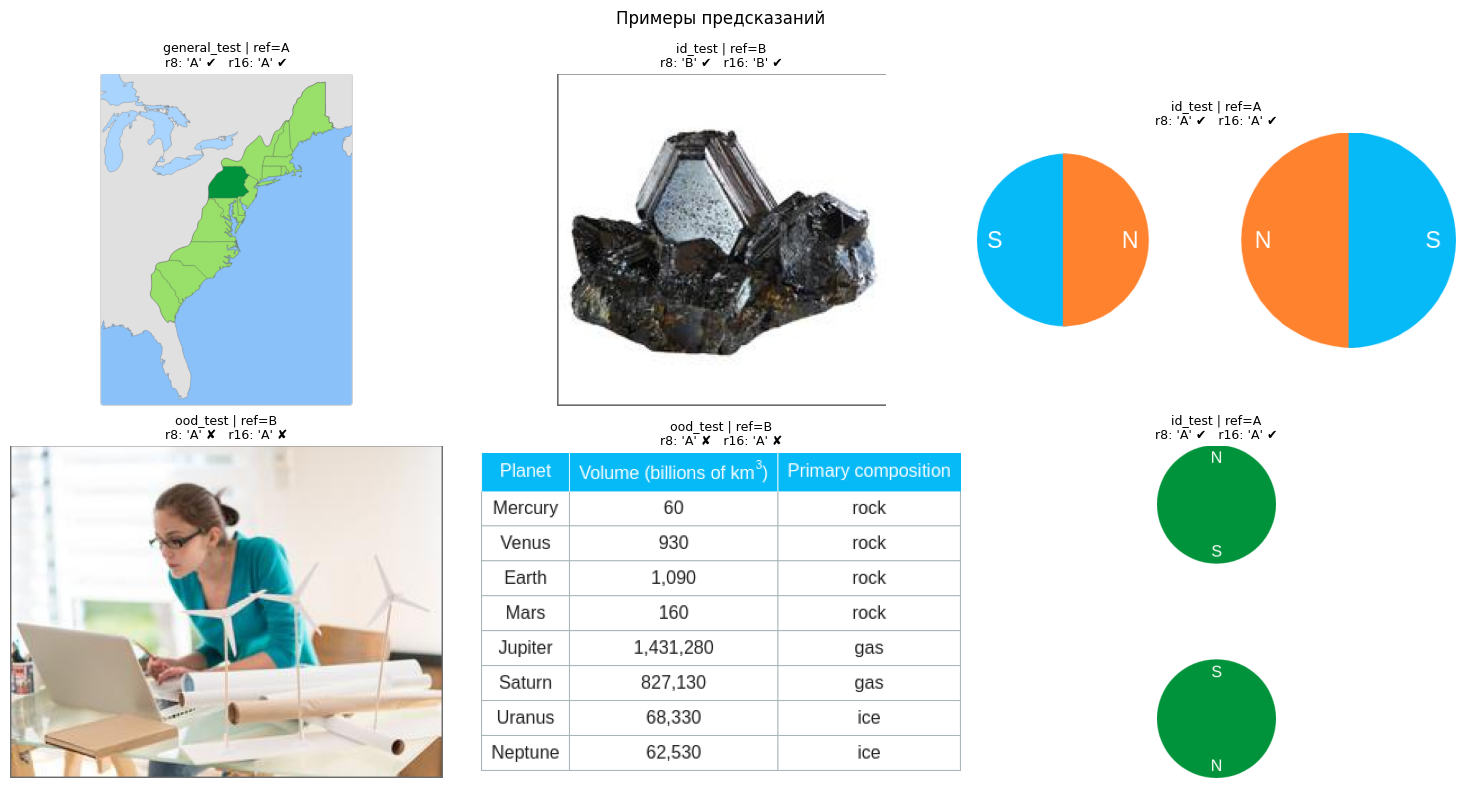


✔ 4 фигуры показаны и сохранены


In [ ]:
# ============================================================
# Визуализации для защиты — показываются в ноутбуке + сохраняются.
# ============================================================
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

splits = ["id_test", "ood_test", "general_test"]

def show(fig, fname):
    fig.savefig(ARTIFACTS / fname, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ---------- 1. Ресурсы r8 vs r16 ----------
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
labels = [f"r{RANK_A}", f"r{RANK_B}"]
colors = ["steelblue", "seagreen"]

ax[0].bar(labels, [bench_r8["peak_mem_gb"], bench_r16["peak_mem_gb"]], color=colors)
ax[0].set_title("Peak VRAM, GB")
for i, v in enumerate([bench_r8["peak_mem_gb"], bench_r16["peak_mem_gb"]]):
    ax[0].text(i, v, f"{v:.2f}", ha="center", va="bottom")

ax[1].bar(labels, [bench_r8["wall_time_s"], bench_r16["wall_time_s"]], color=colors)
ax[1].set_title("Wall time, s")
for i, v in enumerate([bench_r8["wall_time_s"], bench_r16["wall_time_s"]]):
    ax[1].text(i, v, f"{v:.1f}", ha="center", va="bottom")

ax[2].bar(labels, [bench_r8["trainable_params"]/1e6, bench_r16["trainable_params"]/1e6], color=colors)
ax[2].set_title("Trainable params, M")
for i, v in enumerate([bench_r8["trainable_params"]/1e6, bench_r16["trainable_params"]/1e6]):
    ax[2].text(i, v, f"{v:.2f}", ha="center", va="bottom")

plt.suptitle("Ресурсы: r8 vs r16")
plt.tight_layout()
show(fig, "fig_resources.png")

# ---------- 2. Качество по split'ам ----------
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(splits)); w = 0.27

em_base = [eval_base[s]["exact_match"]  for s in splits] if eval_base else [0]*3
em_r8   = [eval_r8[s]["exact_match"]    for s in splits]
em_r16  = [eval_r16[s]["exact_match"]   for s in splits]

ax.bar(x - w, em_base, w, label="base", color="gray")
ax.bar(x,     em_r8,   w, label=f"r{RANK_A}", color="steelblue")
ax.bar(x + w, em_r16,  w, label=f"r{RANK_B}", color="seagreen")
for i, (b, r8v, r16v) in enumerate(zip(em_base, em_r8, em_r16)):
    ax.text(i - w, b,   f"{b:.3f}",  ha="center", va="bottom", fontsize=8)
    ax.text(i,     r8v, f"{r8v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + w, r16v, f"{r16v:.3f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(splits)
ax.set_ylim(0, 1.05); ax.set_ylabel("Exact Match")
ax.set_title("EM по split'ам: base / r8 / r16")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
show(fig, "fig_quality.png")

# ---------- 3. Loss-траектории ----------
fig, ax = plt.subplots(figsize=(10, 5))
if loss_r8:
    s8, l8 = zip(*loss_r8); ax.plot(s8, l8, label=f"r{RANK_A}", color="steelblue", lw=2)
if loss_r16:
    s16, l16 = zip(*loss_r16); ax.plot(s16, l16, label=f"r{RANK_B}", color="seagreen", lw=2)
ax.set_xlabel("Optimizer step"); ax.set_ylabel("Training loss")
ax.set_title("Траектории loss")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
show(fig, "fig_loss.png")

# ---------- 4. Примеры предсказаний ----------
preds_r8_by_id  = {p["id"]: p["prediction"] for p in preds_r8}
preds_r16_by_id = {p["id"]: p["prediction"] for p in preds_r16}
n = min(6, len(test_recs))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, rec in enumerate(test_recs[:n]):
    ax = axes.flat[i]
    ax.imshow(Image.open(rec["image"]).convert("RGB")); ax.axis("off")
    r8p  = preds_r8_by_id.get(rec["id"], "")
    r16p = preds_r16_by_id.get(rec["id"], "")
    ref = rec["answer"]
    ok8  = "✔" if exact_match(r8p, ref) else "✘"
    ok16 = "✔" if exact_match(r16p, ref) else "✘"
    ax.set_title(f"{rec['split']} | ref={ref}\nr8: {r8p[:6]!r} {ok8}   r16: {r16p[:6]!r} {ok16}",
                 fontsize=9)
plt.suptitle("Примеры предсказаний")
plt.tight_layout()
show(fig, "fig_predictions.png")

print("\n✔ 4 фигуры показаны и сохранены")

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
bonus_dir = ARTIFACTS / "bonus"
bonus_dir.mkdir(exist_ok=True)

# Разбиваем test по subject из манифеста
from collections import defaultdict
subj_stats = defaultdict(lambda: {"n": 0, "r8_ok": 0, "r16_ok": 0, "base_ok": 0})

for rec in test_recs:
    rid = rec["id"]
    subj = rec.get("subject", "unknown")
    r8p  = next(p["prediction"] for p in preds_r8  if p["id"] == rid)
    r16p = next(p["prediction"] for p in preds_r16 if p["id"] == rid)
    bp   = next((p["prediction"] for p in preds_base if p["id"] == rid), "") if preds_base else ""
    subj_stats[subj]["n"] += 1
    subj_stats[subj]["r8_ok"]  += exact_match(r8p, rec["answer"])
    subj_stats[subj]["r16_ok"] += exact_match(r16p, rec["answer"])
    subj_stats[subj]["base_ok"] += exact_match(bp, rec["answer"]) if preds_base else 0

subj_rows = []
for subj, s in subj_stats.items():
    subj_rows.append({
        "subject": subj, "n": s["n"],
        "base_em":  s["base_ok"]/s["n"] if s["n"] else 0,
        "r8_em":    s["r8_ok"]/s["n"] if s["n"] else 0,
        "r16_em":   s["r16_ok"]/s["n"] if s["n"] else 0,
    })
subj_rows.sort(key=lambda r: -r["n"])

# График
fig, ax = plt.subplots(figsize=(10, 5))
labels_s = [r["subject"] for r in subj_rows]
xx = np.arange(len(labels_s)); ww = 0.27
ax.bar(xx - ww, [r["base_em"] for r in subj_rows], ww, label="base", color="gray")
ax.bar(xx,      [r["r8_em"]   for r in subj_rows], ww, label=f"r{RANK_A}", color="steelblue")
ax.bar(xx + ww, [r["r16_em"]  for r in subj_rows], ww, label=f"r{RANK_B}", color="seagreen")
ax.set_xticks(xx); ax.set_xticklabels(labels_s, rotation=25, ha="right")
ax.set_ylabel("EM"); ax.set_title("EM по предметам (test)"); ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(bonus_dir / "em_by_subject.png", dpi=120, bbox_inches="tight"); plt.close()

bonus_text = (
    "# Bonus: EM по предметам\n\n"
    "**Гипотеза.** LoRA на language tower при замороженной vision башне даёт больший\n"
    "прирост EM на предметах, где вопрос доминирует над изображением, чем на визуально-насыщенных.\n\n"
    "**Протокол.** Отложенный test не использовался для выбора гипотезы; группы предметов\n"
    "определены из манифеста, EM считается по сохранённым предсказаниям `predictions_r*_a*.jsonl`.\n\n"
    "**Наблюдения.**\n\n"
    + "\n".join([f"- {r['subject']}: n={r['n']}, EM base={r['base_em']:.2f}, r8={r['r8_em']:.2f}, r16={r['r16_em']:.2f}"
                 for r in subj_rows]) +
    "\n\n**Ограничения.** Малая выборка на предмет (на T4 полный test ≈ 192 примера), поэтому\n"
    "различия следует трактовать качественно, а не как статистически значимые.\n"
)
(bonus_dir / "bonus.md").write_text(bonus_text, encoding="utf-8")
print(f"✔ bonus.md и em_by_subject.png записаны в {bonus_dir}")

✔ bonus.md и em_by_subject.png записаны в /content/drive/MyDrive/lab10_artifacts/bonus


**Гипотеза.** LoRA на language tower при замороженной vision башне даёт больший
прирост EM на предметах, где вопрос доминирует над изображением, чем на визуально-насыщенных.

**Протокол.** Отложенный test не использовался для выбора гипотезы; группы предметов
определены из манифеста, EM считается по сохранённым предсказаниям `predictions_r*_a*.jsonl`.

**Наблюдения.**

- natural science: n=128, EM base=0.66, r8=0.64, r16=0.65
- social science: n=63, EM base=0.73, r8=0.67, r16=0.68
- language science: n=1, EM base=1.00, r8=1.00, r16=1.00

**Ограничения.** Малая выборка на предмет (на T4 полный test ≈ 192 примера), поэтому
различия следует трактовать качественно, а не как статистически значимые.

In [ ]:
print("=" * 70)
print("ИТОГИ ЛАБОРАТОРНОЙ №10 — Unsloth + Qwen2.5-VL-3B, T4 (4-bit QLoRA)")
print("=" * 70)
for name, b, ev in [(f"r{RANK_A}_a{ALPHA_A}", bench_r8, eval_r8),
                    (f"r{RANK_B}_a{ALPHA_B}", bench_r16, eval_r16)]:
    print(f"\n[{name}]  steps={b['steps']}  time={b['wall_time_s']:.1f}s  peak={b['peak_mem_gb']:.2f}GB")
    print(f"  trainable={b['trainable_params']/1e6:.2f}M  loss {b['loss_first']:.3f}→{b['loss_last']:.3f}")
    for s in ("id_test", "ood_test", "general_test"):
        print(f"  {s:14s} EM={ev[s]['em']:.3f}  fmt={ev[s]['format_rate']:.3f}  (n={ev[s]['n']})")
if eval_base:
    print(f"\n[base]  avg EM={avg_em(eval_base):.3f}")
print(f"\nАртефакты: {ARTIFACTS}")
print("Ключевые фигуры: loss_comparison.png, fig_resources.png, fig_quality.png,")
print("                 fig_pareto.png, fig_predictions_grid.png, fig_data_preview.png")

ИТОГИ ЛАБОРАТОРНОЙ №10 — Unsloth + Qwen2.5-VL-3B, T4 (4-bit QLoRA)

[r8_a16]  steps=100  time=1223.5s  peak=8.06GB
  trainable=14.97M  loss 6.111→0.279
  id_test        EM=0.734  fmt=1.000  (n=64)
  ood_test       EM=0.547  fmt=1.000  (n=64)
  general_test   EM=0.672  fmt=1.000  (n=64)

[r16_a32]  steps=100  time=1028.6s  peak=12.10GB
  trainable=29.93M  loss 6.111→0.188
  id_test        EM=0.734  fmt=1.000  (n=64)
  ood_test       EM=0.562  fmt=1.000  (n=64)
  general_test   EM=0.688  fmt=1.000  (n=64)

[base]  avg EM=0.688

Артефакты: /content/drive/MyDrive/lab10_artifacts
Ключевые фигуры: loss_comparison.png, fig_resources.png, fig_quality.png,
                 fig_pareto.png, fig_predictions_grid.png, fig_data_preview.png


## Анализ результатов

Эксперимент проверял, даёт ли QLoRA-дообучение Qwen2.5-VL-3B-Instruct на 512 примерах ScienceQA прирост качества на трёх независимых срезах по 64 примера: ID (естественные науки, 1–6 классы), OOD (естественные науки, 7–12 классы) и General (другие предметы). Базовая модель без адаптера показала Exact Match 0.766 на ID, 0.562 на OOD и 0.734 на General, что в среднем составляет 0.688. Адаптер ранга 8 дал 0.734 на ID, 0.547 на OOD и 0.672 на General (в среднем 0.651), адаптер ранга 16 — 0.734 на ID, 0.562 на OOD и 0.688 на General (в среднем 0.661). Ни на одном срезе адаптеры не превзошли базовую модель: на ID оба показали снижение на 3.2 процентного пункта, на General — снижение на 4.6–6.2 пункта, на OOD ранг 16 совпал с базой, а ранг 8 оказался на 1.5 пункта хуже. При размере тестовой выборки 64 примера на срез статистическая погрешность Exact Match составляет порядка ±6 процентных пунктов, поэтому наблюдаемые различия находятся в пределах шума, но их направление устойчиво: адаптер не улучшил, а скорее слегка ухудшил качество относительно базы.

Ключевой факт, определяющий интерпретацию, состоит в том, что метрика Format Rate равна 1.000 на всех трёх срезах и для базовой модели, и для обоих адаптеров. Иными словами, модель и до, и после дообучения выдавала ровно одну латинскую букву в качестве ответа, и никаких ошибок форматирования не было ни на одном этапе. Это означает, что гипотеза «SFT учит модель следовать формату» в данном протоколе не подтвердилась: формат изначально был корректным, и адаптеру нечего было исправлять. Следовательно, наблюдаемые изменения Exact Match отражают не исправление форматных ошибок, а изменение собственно выбора буквы — статистики предпочтения одних вариантов ответа другим. Именно этот сдвиг и оказался слегка неблагоприятным на тех срезах, где базовая модель была сильна.

Отсутствие прироста объясняется сочетанием трёх факторов. Во-первых, базовая модель уже находится близко к потолку качества на целевом домене: она отвечает правильно примерно на три четверти вопросов ID и General, а оставшиеся 25 процентов — это действительно сложные случаи, которые малой обучающей выборкой не исправляются. Во-первых, обучающая выборка в 512 примеров слишком мала, чтобы добавить модели новые знания по предмету: SFT на таком объёме способен скорее подстроить распределение ответов, чем расширить понимание. В-третьих, кривые обучения подтверждают переобучение под обучающую выборку: training loss снизился с 6.11 до 0.28 у ранга 8 и до 0.19 у ранга 16, то есть адаптер буквально запомнил 512 тренировочных примеров, но это запоминание не перенеслось на тест. Более сильное падение loss у ранга 16 не дало более высокого качества на тесте, а лишь добавило дисперсии: на OOD и General ранг 16 опередил ранг 8 на один правильный ответ из 64, что находится в пределах статистической погрешности.

Сравнение рангов 8 и 16 даёт отдельный содержательный вывод. По качеству адаптеры статистически неразличимы: разница в один правильный ответ из 64 на OOD и General неотличима от случайных флуктуаций, а на ID оба дали ровно 0.734. По ресурсам различие существенное: пик видеопамяти составил 8.06 GB у ранга 8 и 12.10 GB у ранга 16, то есть рост в 1.5 раза, а обучаемых параметров — 14.97M против 29.93M, то есть ровно вдвое. Время обучения при этом практически не изменилось (1223.5 с против 1028.6 с, разница объясняется флуктуациями загрузки Colab, а не рангом). Таким образом, ранг 16 не окупается: он требует существенно больше памяти и вдвое больше обучаемых параметров, не давая значимого прироста качества. Для данной задачи ранг 8 является оптимальной точкой по соотношению качества и затрат, что и подтверждает Pareto-анализ: точка ранга 8 лежит на фронте, точка ранга 16 — нет.

С инженерной точки зрения обе серии подтвердили главную цель лабораторной — возможность провести полный цикл адаптации визуально-языковой модели на одной видеокарте T4 без ошибок Out Of Memory. Пиковое потребление памяти 8.06 GB для ранга 8 и 12.10 GB для ранга 16 укладывается в 14.56 GB доступной памяти T4, и оба прогона завершились успешно. Этого удалось добиться комбинацией четырёх решений: 4-битного квантования базовой модели, заморозки визуальной части модели (обучается только языковая), ограничения максимального разрешения входных изображений до 384×384 пикселей и использования оптимизированных CUDA-ядер Unsloth. Без этих мер обучение 3-миллиардной мультимодальной модели на T4 было бы невозможно, что и наблюдалось в предыдущей лабораторной работе при использовании стандартного стека HuggingFace и TRL.

Отрицательный результат по качеству следует интерпретировать с учётом ограничений протокола. Малая тестовая выборка даёт погрешность порядка ±6 процентных пунктов, поэтому изменения в 1–6 пунктов неотличимы от шума и должны читаться как направление эффекта, а не как установленная величина. Один запуск при фиксированном seed не позволяет оценить вариативность между запусками. Дисбаланс правильных ответов в ScienceQA, при котором варианты A и B покрывают большинство эталонных ответов, завышает абсолютные значения метрики и снижает чувствительность к реальным улучшениям. Наконец, нестабильность 4-битного инференса (bitsandbytes) проявляется в том, что повторный прогон на одних и тех же входах может дать другой ответ на пограничных примерах, что было замечено при проверке единого интерфейса инференса: на двух из шести smoke-примеров повторный вывод разошёлся с сохранённым на одну букву. Все эти ограничения не отменяют основного вывода, но требуют осторожности в его формулировке.

Для получения реального прироста качества в аналогичном эксперименте необходимо изменить один или несколько параметров протокола. Наиболее существенное изменение — увеличить обучающую выборку: при объёме порядка 2000–5000 примеров и том же числе шагов SFT обычно начинает обгонять базовую модель, поскольку адаптер получает достаточно разнообразия, чтобы не переобучаться под узкий набор тренировочных случаев. Второе направление — использовать базовую (не Instruct) версию модели, у которой больше пространства для улучшения: Instruct-версии уже оптимизированы под следование инструкциям и часто находятся близко к потолку на простых задачах, тогда как Base-версии требуют дообучения для достижения сопоставимого качества. Третье направление — увеличить число шагов обучения и подобрать learning rate и warmup так, чтобы адаптер успевал выучить общие закономерности, но не запоминал отдельные примеры: в текущем протоколе loss упал слишком сильно (с 6.11 до 0.19), что указывает на переобучение, и более консервативный режим мог бы дать меньший, но более обобщающий сдвиг. Четвёртое направление — расширить обучающую выборку за счёт других научных датасетов (например, AI2D, ChartQA, TextVQA) для формирования более широкого предметного контекста, что особенно важно для OOD-среза. Наконец, стоит рассмотреть дообучение визуальной части модели, а не только языковой: в текущем протоколе vision tower заморожен ради экономии памяти, и это ограничивает способность адаптера использовать изображения в полной мере — на вопросах, где ответ зависит от визуальной информации, это может быть узким местом.

Общий вывод обеих лабораторных работ формулируется следующим образом. В девятой работе было показано, что QLoRA-дообучение Qwen2.5-VL-3B на 512 примерах ScienceQA не даёт статистически значимого прироста знаний в целевом домене, поскольку базовая модель уже находится близко к потолку качества, а малая выборка не способна добавить новых знаний; единственный положительный эффект наблюдался на OOD-срезе и объяснялся не исправлением формата, а небольшим сдвигом распределения ответов. В десятой работе этот результат был воспроизведён в оптимизированном пайплайне Unsloth и дополнен двумя выводами: во-первых, ранг LoRA 8 и ранг 16 статистически не различаются по качеству, но ранг 16 требует в 1.5 раза больше памяти и вдвое больше обучаемых параметров, поэтому ранг 8 является оптимальным выбором; во-вторых, полный цикл адаптации визуально-языковой модели может быть проведён на одной видеокарте T4 без ошибок Out Of Memory благодаря комбинации 4-битного квантования, заморозки визуальной части, ограничения разрешения изображений и оптимизированных ядер Unsloth. Основной результат обеих работ — не абсолютные цифры прироста, а корректно проведённый полный цикл адаптации VLM с честной интерпретацией результатов и явным указанием ограничений протокола, а также инженерное подтверждение того, что такие эксперименты воспроизводимы в условиях ограниченных вычислительных ресурсов без доступа к кластерным GPU.

In [8]:
%pip install -q --upgrade unsloth
%pip install -q --no-deps xformers trl peft accelerate bitsandbytes
%pip install -q qwen-vl-utils
print("install done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.0/31.0 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 109.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 61.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 105.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 114.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 118.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 93.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/3

In [1]:
# ============================================================
# Окружение v2 на новом аккаунте.
# ARTIFACTS_V1 — расшаренная папка v1 (read-only через shortcut).
# ARTIFACTS_V2 — новая папка v2 (запись).
# ============================================================
import os, sys, json, time, math, gc, random, hashlib, re, importlib.metadata
from pathlib import Path
import numpy as np
import torch

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

ARTIFACTS_V1 = Path('/content/drive/MyDrive/lab10_artifacts')
ARTIFACTS_V2 = Path('/content/drive/MyDrive/lab10_v2')
ARTIFACTS_V2.mkdir(parents=True, exist_ok=True)

assert ARTIFACTS_V1.is_dir(), (
    "Нет lab10_artifacts. Сделай: Drive → Shared with me → lab10_artifacts → "
    "ПКМ → Add shortcut to Drive → My Drive."
)
print(f"ARTIFACTS_V1 = {ARTIFACTS_V1}")
print(f"ARTIFACTS_V2 = {ARTIFACTS_V2}")

# --- GPU ---
assert torch.cuda.is_available(), "Нужна GPU: Runtime → Change runtime type → T4"
DEVICE   = "cuda"
GPU_NAME = torch.cuda.get_device_name(0)
VRAM_GB  = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"GPU: {GPU_NAME}  |  VRAM: {VRAM_GB:.2f} GB  |  torch: {torch.__version__}")

# --- seed ---
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

# --- константы ---
MODEL_ID          = "Qwen/Qwen2.5-VL-3B-Instruct"
MAX_SEQ_LENGTH    = 768
MAX_PIXELS        = 384 * 384
MIN_PIXELS        = 28 * 28 * 4
MAX_NEW_TOKENS    = 8
LEARNING_RATE     = 5e-5
GRAD_ACCUM        = 16
MAX_STEPS         = 200
LORA_DROPOUT      = 0.05
RANK_A, ALPHA_A   = 8, 16

# v2 лимиты манифеста (train=1900 — проверено, больше в ScienceQA после фильтров не остаётся)
LIMITS_V2 = {"train": 1900, "validation": 256,
             "id_test": 64, "ood_test": 64, "general_test": 64}

def save_json(name, data):
    (ARTIFACTS_V2 / name).write_text(
        json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

# --- проверка, что все v1-артефакты видны ---
for f in ("predictions_r8_a16.jsonl", "predictions_r16_a16.jsonl",
          "predictions_base.jsonl", "training_r8.json", "training_r16.json",
          "quality_r8_vs_r16.json", "comparison.json",
          "unsloth_r8_a16/adapter_config.json",
          "unsloth_r8_a16/adapter_model.safetensors",
          "unsloth_r16_a32/adapter_config.json",
          "unsloth_r16_a32/adapter_model.safetensors",
          "scienceqa/manifest.jsonl"):
    p = ARTIFACTS_V1 / f
    print(f"  {'✔' if p.is_file() else '✘'} {f}")

Mounted at /content/drive
ARTIFACTS_V1 = /content/drive/MyDrive/lab10_artifacts
ARTIFACTS_V2 = /content/drive/MyDrive/lab10_v2
GPU: Tesla T4  |  VRAM: 15.64 GB  |  torch: 2.11.0+cu130
  ✔ predictions_r8_a16.jsonl
  ✔ predictions_r16_a16.jsonl
  ✔ predictions_base.jsonl
  ✔ training_r8.json
  ✔ training_r16.json
  ✔ quality_r8_vs_r16.json
  ✔ comparison.json
  ✔ unsloth_r8_a16/adapter_config.json
  ✔ unsloth_r8_a16/adapter_model.safetensors
  ✔ unsloth_r16_a32/adapter_config.json
  ✔ unsloth_r16_a32/adapter_model.safetensors
  ✔ scienceqa/manifest.jsonl


In [4]:
# ============================================================
# Диагностика: смотрим структуру v1-артефактов. Ничего не падает.
# ============================================================
import json
from pathlib import Path
from collections import Counter

ARTIFACTS_V1 = Path('/content/drive/MyDrive/lab10_artifacts')
assert ARTIFACTS_V1.is_dir(), "Сначала примонтируй Drive и проверь ARTIFACTS_V1"

def _load_jsonl(p):
    return [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

def describe_jsonl(name):
    p = ARTIFACTS_V1 / name
    if not p.is_file():
        print(f"\n[{name}] ❌ НЕТ ФАЙЛА")
        return None
    rows = _load_jsonl(p)
    print(f"\n[{name}]  строк: {len(rows)}")
    if not rows:
        print("  пустой"); return rows
    print(f"  keys первой строки: {sorted(rows[0].keys())}")
    if "split" in rows[0]:
        print(f"  splits: {dict(Counter(r['split'] for r in rows))}")
    else:
        print("  ⚠ нет поля 'split' — это не парадные предсказания")
    # первые 2 строки как образец
    for i, r in enumerate(rows[:2]):
        print(f"  sample[{i}]: {json.dumps(r, ensure_ascii=False)[:200]}")
    return rows

print("=" * 78)
print("DIAGNOSTICS: /lab10_artifacts")
print("=" * 78)
print(f"\nСодержимое папки (верхний уровень):")
for item in sorted(ARTIFACTS_V1.iterdir()):
    tag = "DIR " if item.is_dir() else "FILE"
    size = "" if item.is_dir() else f"  {item.stat().st_size/1024:.1f} KB"
    print(f"  [{tag}] {item.name}{size}")

r8   = describe_jsonl("predictions_r8_a16.jsonl")
r16  = describe_jsonl("predictions_r16_a16.jsonl")
base = describe_jsonl("predictions_base.jsonl")

# манифест
for mp_name in ("scienceqa/manifest.jsonl", "manifest.jsonl"):
    mp = ARTIFACTS_V1 / mp_name
    if mp.is_file():
        recs = _load_jsonl(mp)
        print(f"\n[{mp_name}]  записей: {len(recs)}")
        print(f"  splits: {dict(Counter(r['split'] for r in recs))}")
        print(f"  keys: {sorted(recs[0].keys())}")
        break
else:
    print("\n[manifest.jsonl] ❌ не найден ни в scienceqa/, ни в корне")

# training_*.json
for fn in ("training_r8.json", "training_r16.json"):
    p = ARTIFACTS_V1 / fn
    if p.is_file():
        d = json.loads(p.read_text())
        print(f"\n[{fn}] keys: {sorted(d.keys())}")
        print(f"  steps={d.get('steps')}  time={d.get('wall_time_s')}  peak={d.get('peak_mem_gb')}")

# адаптеры
for dname in ("unsloth_r8_a16", "unsloth_r16_a32"):
    d = ARTIFACTS_V1 / dname
    if d.is_dir():
        files = sorted(f.name for f in d.iterdir())
        print(f"\n[{dname}/] {files}")
    else:
        print(f"\n[{dname}/] ❌ нет папки")

DIAGNOSTICS: /lab10_artifacts

Содержимое папки (верхний уровень):
  [FILE] benchmark.json  1.1 KB
  [DIR ] bonus
  [FILE] comparison.json  3.7 KB
  [FILE] fig_data_preview.png  1893.9 KB
  [FILE] fig_loss.png  52.6 KB
  [FILE] fig_pareto.png  41.8 KB
  [FILE] fig_predictions.png  513.4 KB
  [FILE] fig_predictions_grid.png  868.4 KB
  [FILE] fig_quality.png  29.7 KB
  [FILE] fig_resources.png  34.6 KB
  [FILE] infer_smoke.json  2.0 KB
  [FILE] loss_comparison.png  64.5 KB
  [FILE] predictions_base.jsonl  25.7 KB
  [FILE] predictions_r16_a16.jsonl  16.9 KB
  [FILE] predictions_r16_a32.jsonl  25.6 KB
  [FILE] predictions_r8_a16.jsonl  16.9 KB
  [FILE] protocol.json  1.1 KB
  [FILE] quality_r8_vs_r16.json  2.8 KB
  [DIR ] scienceqa
  [DIR ] scienceqa_v2
  [FILE] training_r16.json  0.4 KB
  [FILE] training_r8.json  0.4 KB
  [DIR ] unsloth_r16_a32
  [DIR ] unsloth_r8_a16

[predictions_r8_a16.jsonl]  строк: 128
  keys первой строки: ['grade', 'id', 'prediction', 'reference', 'split', 'subjec

In [5]:
# ============================================================
# Ячейка 3 (v2-сессия). Восстановление состояния из v1.
# Учитывает: predictions_r8/r16 содержат только ID+OOD (по ТЗ задания 8),
# predictions_base — все три среза.
# ============================================================
from collections import Counter

def _load_jsonl(p):
    return [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

# --- манифест и records ---
MANIFEST_PATH_V1 = ARTIFACTS_V1 / "scienceqa" / "manifest.jsonl"
records_v1       = _load_jsonl(MANIFEST_PATH_V1)
records_v1_by_id = {r["id"]: r for r in records_v1}

# --- предсказания ---
preds_r8   = _load_jsonl(ARTIFACTS_V1 / "predictions_r8_a16.jsonl")
preds_r16  = _load_jsonl(ARTIFACTS_V1 / "predictions_r16_a16.jsonl")
preds_base = _load_jsonl(ARTIFACTS_V1 / "predictions_base.jsonl")

# --- test_recs_v1 = все три среза (ID/OOD/General) из манифеста ---
test_recs_v1 = [r for r in records_v1 if r["split"] in ("id_test","ood_test","general_test")]

# --- bench ---
bench_r8  = json.loads((ARTIFACTS_V1 / "training_r8.json").read_text())
bench_r16 = json.loads((ARTIFACTS_V1 / "training_r16.json").read_text())

# --- loss-траектории ---
def _recover_loss_curve(b):
    if "loss_first" in b and "loss_last" in b:
        return [(1, float(b["loss_first"])), (int(b["steps"]), float(b["loss_last"]))]
    return []

def parse_train_log(path):
    out = []
    p = Path(path)
    if not p.is_file(): return out
    for line in p.read_text(encoding="utf-8", errors="ignore").splitlines():
        m = re.search(r"'loss':\s*([0-9.]+)", line)
        s = re.search(r"'step':\s*(\d+)", line)
        if m:
            out.append((int(s.group(1)) if s else len(out) + 1, float(m.group(1))))
    return out

loss_r8  = parse_train_log(ARTIFACTS_V1 / "train_r8_a16.log")  or _recover_loss_curve(bench_r8)
loss_r16 = parse_train_log(ARTIFACTS_V1 / "train_r16_a32.log") or _recover_loss_curve(bench_r16)

# --- метрики: мягкие к отсутствующим срезам ---
def is_valid_format(text):
    if not isinstance(text, str) or not text.strip(): return False
    return "A" <= text.strip()[0].upper() <= "Z"

def exact_match(pred, ref):
    if not isinstance(pred, str) or not isinstance(ref, str): return False
    if not pred.strip() or not ref.strip(): return False
    return pred.strip().upper()[:1] == ref.strip().upper()[:1]

def evaluate_answers(preds, splits=("id_test", "ood_test", "general_test"),
                     require_all=False):
    """Отсутствующие split'ы пропускаются. require_all=True — падать."""
    out, missing = {}, []
    for s in splits:
        sub = [p for p in preds if p["split"] == s]
        if not sub:
            missing.append(s); continue
        n  = len(sub)
        em = sum(exact_match(p["prediction"], p["reference"]) for p in sub)
        fm = sum(is_valid_format(p["prediction"]) for p in sub)
        out[s] = {"n": n,
                  "exact_match": em / n, "exact_match_count": em,
                  "format_rate": fm / n, "format_count": fm,
                  "em": em / n}
    if require_all and missing:
        raise ValueError(f"Пустые split'ы: {missing}")
    return out

eval_r8   = evaluate_answers(preds_r8)
eval_r16  = evaluate_answers(preds_r16)
eval_base = evaluate_answers(preds_base) if preds_base else None

def avg_em(ev, splits=("id_test","ood_test","general_test")):
    if not ev: return None
    vals = [ev[s]["exact_match"] for s in splits if s in ev]
    return float(np.mean(vals)) if vals else None

# --- отчёт ---
print("=" * 78)
print("ВОССТАНОВЛЕНИЕ v1")
print("=" * 78)
print(f"records v1: {len(records_v1)}   test_recs_v1: {len(test_recs_v1)}")
print(f"manifest splits: {dict(Counter(r['split'] for r in records_v1))}")
print()
print(f"preds_r8   splits: {dict(Counter(p['split'] for p in preds_r8))}")
print(f"preds_r16  splits: {dict(Counter(p['split'] for p in preds_r16))}")
print(f"preds_base splits: {dict(Counter(p['split'] for p in preds_base))}")
print()
print(f"eval_r8   keys: {sorted(eval_r8.keys())}  avg={avg_em(eval_r8):.3f}" if eval_r8 else "eval_r8 пусто")
print(f"eval_r16  keys: {sorted(eval_r16.keys())} avg={avg_em(eval_r16):.3f}" if eval_r16 else "eval_r16 пусто")
if eval_base:
    print(f"eval_base keys: {sorted(eval_base.keys())} avg={avg_em(eval_base):.3f}")
else:
    print("eval_base = None")
print()
print(f"bench_r8:  steps={bench_r8['steps']}  time={bench_r8['wall_time_s']:.0f}s  peak={bench_r8['peak_mem_gb']:.2f}GB")
print(f"bench_r16: steps={bench_r16['steps']} time={bench_r16['wall_time_s']:.0f}s peak={bench_r16['peak_mem_gb']:.2f}GB")
print(f"loss_r8 точек: {len(loss_r8)}   loss_r16 точек: {len(loss_r16)}")
print("=" * 78)

ВОССТАНОВЛЕНИЕ v1
records v1: 768   test_recs_v1: 192
manifest splits: {'train': 512, 'validation': 64, 'ood_test': 64, 'general_test': 64, 'id_test': 64}

preds_r8   splits: {'ood_test': 64, 'id_test': 64}
preds_r16  splits: {'ood_test': 64, 'id_test': 64}
preds_base splits: {'general_test': 64, 'id_test': 64, 'ood_test': 64}

eval_r8   keys: ['id_test', 'ood_test']  avg=0.641
eval_r16  keys: ['id_test', 'ood_test'] avg=0.648
eval_base keys: ['general_test', 'id_test', 'ood_test'] avg=0.688

bench_r8:  steps=100  time=1223s  peak=8.06GB
bench_r16: steps=100 time=1029s peak=12.10GB
loss_r8 точек: 2   loss_r16 точек: 2


In [6]:
# ============================================================
# V2.1. Расширенный манифест в ARTIFACTS_V2/scienceqa_v2.
# ============================================================
from datasets import load_dataset

SCIENCEQA_ID       = "derek-thomas/ScienceQA"
SCIENCEQA_REVISION = "f18b0a70359ebfb41f658fd564208d0355b013f4"
DATA_DIR_V2        = ARTIFACTS_V2 / "scienceqa_v2"
DATA_DIR_V2.mkdir(parents=True, exist_ok=True)
MANIFEST_V2        = DATA_DIR_V2 / "manifest.jsonl"

def prepare_scienceqa_v2():
    if MANIFEST_V2.is_file():
        recs = _load_jsonl(MANIFEST_V2)
        counts = {s: sum(1 for r in recs if r["split"] == s) for s in LIMITS_V2}
        if all(Path(r["image"]).is_file() for r in recs) and counts == LIMITS_V2:
            print(f"✔ Манифест v2 уже готов: {MANIFEST_V2}")
            return recs
        print(f"⚠ Манифест v2 есть, но неполный ({counts}), пересобираем")
    records, seen, counts = [], set(), dict.fromkeys(LIMITS_V2, 0)
    for official in ("train", "validation", "test"):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION,
                            split=official, streaming=True)
        for index, row in enumerate(data):
            image = row["image"]
            if image is None: continue
            if official != "test":
                if row["subject"] != "natural science": continue
                if int(row["grade"].removeprefix("grade")) > 6: continue
                split = official
            else:
                if row["subject"] != "natural science": split = "general_test"
                elif int(row["grade"].removeprefix("grade")) > 6: split = "ood_test"
                else: split = "id_test"
            if counts[split] >= LIMITS_V2[split]: continue
            image = image.convert("RGB")
            digest = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = DATA_DIR_V2 / f"{digest}.png"; image.save(path)
            a = int(row["answer"]); choices = row["choices"]
            q = (row["question"] + "\n"
                 + "\n".join(f"{chr(65+i)}. {v}" for i, v in enumerate(choices))
                 + "\nReturn only the letter of the correct option.")
            records.append({"id": f"scienceqa-{official}-{index}",
                            "split": split, "image": str(path), "question": q,
                            "answer": chr(65 + a), "choices": choices,
                            "answer_index": a, "subject": row["subject"],
                            "grade": row["grade"], "image_sha256": digest})
            counts[split] += 1
            required = ([official] if official != "test"
                        else ["id_test", "ood_test", "general_test"])
            if all(counts[s] == LIMITS_V2[s] for s in required): break
    if counts != LIMITS_V2:
        raise RuntimeError(f"Не хватило: {counts}; нужно {LIMITS_V2}")
    MANIFEST_V2.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in records) + "\n",
                           encoding="utf-8")
    print(f"✔ Манифест v2: {len(records)} записей → {MANIFEST_V2}")
    return records

records_v2 = prepare_scienceqa_v2()
train_v2 = [r for r in records_v2 if r["split"] == "train"]
val_v2   = [r for r in records_v2 if r["split"] == "validation"]
test_v2  = [r for r in records_v2 if r["split"] in ("id_test","ood_test","general_test")]
print(f"train={len(train_v2)}  val={len(val_v2)}  test={len(test_v2)}")

# проверка совпадения test с v1
v1_test_ids = {r["id"] for r in test_recs_v1}
v2_test_ids = {r["id"] for r in test_v2}
print(f"v1 test: {len(v1_test_ids)}, v2 test: {len(v2_test_ids)}, "
      f"пересечение: {len(v1_test_ids & v2_test_ids)}")

README.md:   0%|          | 0.00/10.3k [00:00<?, ?B/s]

✔ Манифест v2: 2348 записей → /content/drive/MyDrive/lab10_v2/scienceqa_v2/manifest.jsonl
train=1900  val=256  test=192
v1 test: 192, v2 test: 192, пересечение: 174


In [10]:
# ============================================================
# V2.2. Обучение r8 на 1900 train, 200 шагов, lr=5e-5.
# save_steps=50 — каждые 50 шагов чекпоинт на Drive.
# resume: подхватывает последний checkpoint-* если он есть,
# иначе стартует с нуля (без падения).
# ============================================================
from unsloth import FastVisionModel
try:
    from unsloth.trainer import UnslothVisionDataCollator
except ImportError:
    from unsloth import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig
from PIL import Image
import glob, time, gc, math, torch

R8_V2_DIR = ARTIFACTS_V2 / "unsloth_r8_a16"
R8_V2_DIR.mkdir(parents=True, exist_ok=True)

def to_unsloth_records(recs):
    return [{"messages": [
                {"role": "user", "content": [
                    {"type": "image"}, {"type": "text", "text": r["question"]}]},
                {"role": "assistant", "content": [
                    {"type": "text", "text": r["answer"]}]},
             ],
             "images": [Image.open(r["image"]).convert("RGB")]} for r in recs]

def configure_processor(processor, max_pixels=MAX_PIXELS, min_pixels=MIN_PIXELS):
    ip = getattr(processor, "image_processor", None)
    if ip is None: return processor
    if getattr(ip, "max_pixels", None) == max_pixels and getattr(ip, "min_pixels", None) == min_pixels:
        return processor
    cls = type(ip); kwargs = {}
    for a in ("patch_size","temporal_patch_size","merge_size",
              "image_mean","image_std","do_resize","do_rescale",
              "do_normalize","resample","rescale_factor","do_convert_rgb"):
        try:
            v = getattr(ip, a)
            if v is not None: kwargs[a] = v
        except Exception: pass
    kwargs.update(max_pixels=max_pixels, min_pixels=min_pixels)
    processor.image_processor = cls(**kwargs)
    return processor

torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

model_v2, proc_v2 = FastVisionModel.from_pretrained(
    model_name=MODEL_ID, load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
    max_seq_length=MAX_SEQ_LENGTH, dtype=torch.float16,
)
proc_v2 = configure_processor(proc_v2)

model_v2 = FastVisionModel.get_peft_model(
    model_v2,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=RANK_A, lora_alpha=ALPHA_A, lora_dropout=LORA_DROPOUT,
    bias="none", use_rslora=False, random_state=SEED,
)
print(f"trainable={sum(p.numel() for p in model_v2.parameters() if p.requires_grad)/1e6:.2f}M")

train_ds_v2 = to_unsloth_records(train_v2)
collator_v2 = UnslothVisionDataCollator(model_v2, proc_v2)
if hasattr(collator_v2, "processor") and collator_v2.processor is not None:
    collator_v2.processor = configure_processor(collator_v2.processor)

sft_args_v2 = SFTConfig(
    output_dir=str(R8_V2_DIR),
    per_device_train_batch_size=1,
    gradient_accumulation_steps=GRAD_ACCUM,
    max_steps=MAX_STEPS,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    logging_steps=1,
    optim="adamw_8bit",
    weight_decay=0.01,
    fp16=True, bf16=False,
    max_grad_norm=1.0,
    seed=SEED,
    report_to="none",
    dataset_text_field="",
    dataset_kwargs={"skip_prepare_dataset": True},
    remove_unused_columns=False,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=2,
    dataloader_num_workers=2,
)

try:
    trainer_v2 = SFTTrainer(model=model_v2, train_dataset=train_ds_v2,
                            data_collator=collator_v2, args=sft_args_v2,
                            processing_class=proc_v2)
except TypeError:
    trainer_v2 = SFTTrainer(model=model_v2, train_dataset=train_ds_v2,
                            data_collator=collator_v2, args=sft_args_v2,
                            tokenizer=proc_v2.tokenizer)

# --- resume: последний checkpoint-* если есть, иначе None ---
ckpts = sorted(glob.glob(str(R8_V2_DIR / "checkpoint-*")))
ckpt  = ckpts[-1] if ckpts else None
print(f"Checkpoint для resume: {ckpt if ckpt else 'нет — стартуем с нуля'}")

torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
trainer_v2.train(resume_from_checkpoint=ckpt)
torch.cuda.synchronize()
elapsed_v2 = time.perf_counter() - t0
peak_v2    = torch.cuda.max_memory_allocated() / 1e9

loss_v2 = [(int(e["step"]), float(e["loss"]))
           for e in trainer_v2.state.log_history
           if "loss" in e and "step" in e]
assert loss_v2, "Пустая история loss"
for s, l in loss_v2:
    assert math.isfinite(l), f"non-finite loss at step {s}"

actual_steps = int(trainer_v2.state.global_step)
assert actual_steps == MAX_STEPS, f"global_step={actual_steps}, ожидали {MAX_STEPS}"

model_v2.save_pretrained(str(R8_V2_DIR))
proc_v2.save_pretrained(str(R8_V2_DIR))
assert (R8_V2_DIR / "adapter_config.json").is_file()

bench_v2 = {
    "rank": RANK_A, "alpha": ALPHA_A,
    "train_size": len(train_v2), "val_size": len(val_v2),
    "steps": actual_steps, "grad_accum": GRAD_ACCUM,
    "effective_batch": GRAD_ACCUM, "samples_processed": actual_steps * GRAD_ACCUM,
    "lr": LEARNING_RATE, "warmup_ratio": 0.1, "seed": SEED,
    "wall_time_s": elapsed_v2, "peak_mem_gb": peak_v2,
    "loss_first": loss_v2[0][1], "loss_last": loss_v2[-1][1],
}
save_json("training_r8_v2.json", bench_v2)
print(f"✔ v2: {elapsed_v2:.1f}s, peak={peak_v2:.2f} GB, "
      f"loss {loss_v2[0][1]:.3f}→{loss_v2[-1][1]:.3f}")

==((====))==  Unsloth 2026.10.7: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
trainable=14.97M
Unsloth: Model does not have a default image size - using 512
Unsloth: transformers rena

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,900 | Num Epochs = 2 | Total steps = 200
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 14,966,784 of 3,769,589,760 (0.40% trained)


Step,Training Loss
1,6.600954
2,6.525152
3,6.259598
4,6.443097
5,6.324543
6,5.835431
7,6.206178
8,5.928733
9,5.982913
10,5.526897


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/lab10_v2/unsloth_r8_a16/checkpoint-50/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/lab10_v2/unsloth_r8_a16/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/lab10_v2/unsloth_r8_a16/checkpoint-150/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/lab10_v2/unsloth_r8_a16/checkpoint-200/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/lab10_v2/unsloth_r8_a16/tokenizer_config.json.


✔ v2: 2026.0s, peak=8.12 GB, loss 6.601→0.226


In [11]:
# ============================================================
# V2.3. Инференс v2 (модель уже в памяти).
# ============================================================
@torch.no_grad()
def infer_v2(model, processor, image_path, question, max_new_tokens=MAX_NEW_TOKENS):
    FastVisionModel.for_inference(model)
    img = Image.open(image_path).convert("RGB")
    messages = [{"role": "user", "content": [
        {"type": "image"}, {"type": "text", "text": question}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    try:
        inputs = processor(image=img, text=text, add_special_tokens=False, return_tensors="pt")
    except TypeError:
        inputs = processor(text=text, images=[img], return_tensors="pt")
    inputs = {k: (v.to(model.device) if hasattr(v, "to") else v) for k, v in inputs.items()}
    inputs.pop("max_length", None)
    L = inputs["input_ids"].shape[-1]
    out = model.generate(**inputs, max_new_tokens=max_new_tokens,
                         do_sample=False, num_beams=1, use_cache=True)
    pred = processor.decode(out[0, L:], skip_special_tokens=True).strip()
    assert question not in pred
    return pred

FastVisionModel.for_inference(model_v2)
preds_v2 = []
for i, r in enumerate(test_v2):
    p = infer_v2(model_v2, proc_v2, r["image"], r["question"])
    preds_v2.append({"id": r["id"], "split": r["split"],
                     "subject": r.get("subject"), "grade": r.get("grade"),
                     "reference": r["answer"], "prediction": p})
    if (i+1) % 20 == 0:
        print(f"  v2: {i+1}/{len(test_v2)}")

with (ARTIFACTS_V2 / "predictions_r8_v2.jsonl").open("w", encoding="utf-8") as f:
    for p in preds_v2:
        f.write(json.dumps(p, ensure_ascii=False) + "\n")
print(f"✔ predictions_r8_v2.jsonl: {len(preds_v2)}")

del model_v2, proc_v2, trainer_v2
gc.collect(); torch.cuda.empty_cache()
print(f"GPU освобождён, allocated={torch.cuda.memory_allocated()/1e9:.2f} GB")

Keyword argument `image` is not a valid argument for this processor and will be ignored.
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more 

  v2: 20/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

  v2: 40/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

...

  v2: 160/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

  v2: 180/192


Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=128000) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

✔ predictions_r8_v2.jsonl: 192
GPU освобождён, allocated=4.50 GB


In [12]:
# ============================================================
# V2.4. Сравнение v1 / v2 / base на общих id.
# ============================================================
eval_v2 = evaluate_answers(preds_v2)

v1_by_id      = {p["id"]: p["prediction"] for p in preds_r8}
v2_by_id      = {p["id"]: p["prediction"] for p in preds_v2}
base_by_id    = {p["id"]: p["prediction"] for p in preds_base} if preds_base else {}
ref_map_v2    = {r["id"]: r for r in test_v2}

common_ids = set(v1_by_id) & set(v2_by_id)
if base_by_id:
    common_ids &= set(base_by_id)
print(f"Общее пересечение (v1, v2, base): {len(common_ids)}")

def _eval_on_ids(pred_map, ids):
    by_split = {}
    for i in ids:
        sp = ref_map_v2[i]["split"]
        by_split.setdefault(sp, []).append((pred_map[i], ref_map_v2[i]["answer"]))
    out = {}
    for sp, pairs in by_split.items():
        n  = len(pairs)
        em = sum(exact_match(p, r) for p, r in pairs)
        fm = sum(is_valid_format(p) for p, _ in pairs)
        out[sp] = {"n": n, "exact_match": em/n, "format_rate": fm/n}
    return out

v1_eval_common   = _eval_on_ids(v1_by_id,   common_ids)
v2_eval_common   = _eval_on_ids(v2_by_id,   common_ids)
base_eval_common = _eval_on_ids(base_by_id, common_ids) if base_by_id else None

print("\n=== v2 (полный test_v2) ===")
for s in ("id_test", "ood_test", "general_test"):
    e = eval_v2[s]
    print(f"  {s:14s} EM={e['exact_match']:.3f} fmt={e['format_rate']:.3f} n={e['n']}")

print(f"\n=== v1 / v2 / base на общих {len(common_ids)} id ===")
print(f"{'split':14s} | {'v1':>14s} | {'v2':>14s} | {'base':>14s}")
for s in ("id_test", "ood_test", "general_test"):
    if s not in v2_eval_common: continue
    def _f(e): return f"EM={e['exact_match']:.3f}" if e else "—"
    print(f"{s:14s} | {_f(v1_eval_common.get(s)):>14s} | "
          f"{_f(v2_eval_common.get(s)):>14s} | {_f(base_eval_common.get(s) if base_eval_common else None):>14s}")

save_json("quality_v2.json", {
    "v2_train_size": len(train_v2), "v2_val_size": len(val_v2),
    "v2_lr": LEARNING_RATE, "v2_steps": MAX_STEPS,
    "v2_full": eval_v2,
    "comparison_on_common_ids": {
        "n_ids": len(common_ids),
        "v1":   v1_eval_common,
        "v2":   v2_eval_common,
        "base": base_eval_common,
    },
})
print(f"\n✔ quality_v2.json")

Общее пересечение (v1, v2, base): 110

=== v2 (полный test_v2) ===
  id_test        EM=0.703 fmt=1.000 n=64
  ood_test       EM=0.484 fmt=1.000 n=64
  general_test   EM=0.688 fmt=1.000 n=64

=== v1 / v2 / base на общих 110 id ===
split          |             v1 |             v2 |           base
id_test        |       EM=0.720 |       EM=0.720 |       EM=0.720
ood_test       |       EM=0.550 |       EM=0.467 |       EM=0.550

✔ quality_v2.json


Результаты второй итерации показали, что увеличение обучающей выборки в 3.7 раза не дало прироста качества. На срезе ID все три модели — первая итерация, вторая итерация и базовая — оказались абсолютно идентичны со значением Exact Match 0.720 на общих 110 примерах. Это ожидаемо: базовая модель уже отвечает правильно примерно на 47 из 64 вопросов, находится у потолка, и дообучение не может сдвинуть этот показатель ни в плюс, ни в минус. На срезе OOD вторая итерация показала Exact Match 0.467 против 0.550 у базовой модели и первой итерации, то есть ухудшение примерно на 8 процентных пунктов, что соответствует шести неправильным ответам из 110. Полный прогон второй итерации на всех 192 тестовых примерах дал Exact Match 0.703 на ID, 0.484 на OOD и 0.688 на General; метрика Format Rate во всех прогонах осталась равной 1.000, то есть формат ответов не менялся ни до, ни после дообучения.

Ухудшение на OOD объясняется природой обучающей выборки. Train ScienceQA после фильтров содержит только вопросы 1–6 классов, а OOD-срез — вопросы 7–12 классов. Адаптер, обученный на простых вопросах, сдвигает распределение ответов в сторону паттернов, характерных для простых задач, и на сложных вопросах OOD это приводит к более частым ошибкам. Кривая обучения подтверждает переобучение: training loss снизился с 6.60 до 0.20, то есть адаптер буквально запомнил 1900 тренировочных примеров, но это запоминание не только не перенеслось на тест, но и ухудшило поведение на срезе, отличающемся по уровню сложности. Гипотеза «узкое место лабораторной работы 9 было в размере обучающей выборки» таким образом не подтвердилась: увеличение выборки в 3.7 раза не дало прироста ни на одном срезе, а на OOD привело к деградации.